# Thesis figures, one per cell

Each figure below is drawn by its own cell, reading its own data straight out of the committed
result files under `results/accord/`. No cell depends on any variable another figure's cell
created; each one loads what it needs, prints the values it is about to plot, draws, displays the
figure inline, and saves it as a PDF.

Run cells 1 to 3 first (setup, palette, small shared helpers). After that, every figure cell below
runs on its own, in any order.

**No credentialed data is shipped here.** MIMIC-III is a PhysioNet-credentialed dataset; every
result file this notebook reads is an aggregate (counts, rates, confusion-matrix cells, bootstrap
intervals) with no clinical text and no patient or admission identifiers.

## 1. Setup

In [1]:
%matplotlib inline
import os, sys, shutil, json, pathlib, math, statistics
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import norm
from scipy.optimize import brentq
import pandas as pd

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_BUNDLE = "/content/drive/MyDrive/This is paper/02_figures/colab_bundle"
    REPO = "/content/repo"
    os.makedirs(REPO, exist_ok=True)
    dst_results = os.path.join(REPO, "results")
    if os.path.exists(dst_results):
        shutil.rmtree(dst_results)
    shutil.copytree(os.path.join(DRIVE_BUNDLE, "results"), dst_results)
    print(f"copied bundle results: {DRIVE_BUNDLE}/results -> {dst_results}")
else:
    # Local run: this machine already has the repository checked out, so there is
    # nothing to mount or copy. REPO points straight at it.
    REPO = "/Users/rickygole/provenance-encoder"
    print(f"not running in Colab; reading directly from the local repository at {REPO}")

RESULTS = os.path.join(REPO, "results")
RESULTS_ACCORD = os.path.join(RESULTS, "accord")
FIGDIR = os.path.join(REPO, "accord", "thesis", "figures")
os.makedirs(FIGDIR, exist_ok=True)

# Defensive only: no cell in this notebook resamples or fits anything. Every
# bootstrap interval plotted below was already computed upstream (the seed is
# recorded inside the source JSON, typically 42) and is simply read and plotted.
np.random.seed(42)

n_json = sum(1 for _ in pathlib.Path(RESULTS_ACCORD).rglob("*.json"))
print("REPO           =", REPO)
print("RESULTS_ACCORD =", RESULTS_ACCORD)
print("FIGDIR         =", FIGDIR)
print("json files under results/accord:", n_json)

not running in Colab; reading directly from the local repository at /Users/rickygole/provenance-encoder
REPO           = /Users/rickygole/provenance-encoder
RESULTS_ACCORD = /Users/rickygole/provenance-encoder/results/accord
FIGDIR         = /Users/rickygole/provenance-encoder/accord/thesis/figures
json files under results/accord: 99


## 2. Shared palette

Four colours plus a red accent, used by name in every figure cell below (`DARK`, `MID`, `FILL`,
`DEAD`, `RED`). They differ in **lightness**, not just hue, so the figures still separate correctly
in a black-and-white print; the readout below prints that separation. This is the same palette
already established for this bundle in `Thesis_Figures_Restyle.ipynb`.

In [2]:
# Structure. Unchanged: these five tones draw everything that is not a
# measurement -- type, rules, reference lines, secondary bands, annotation.
INK     = "#1A1A1A"   # text, spines, ticks
MUTE    = "#5B5B5B"   # secondary annotation text
GREY    = "#8A94A6"   # reference lines, seed dots
PALE    = "#C9D2E3"   # secondary bands
GRID    = "#E8E8E8"   # the one optional hairline value grid

# The claim tone. Exactly one element per figure: this study, or the failure.
# It is never a series colour, and no series colour is ever asked to be a claim.
SCARLET = "#D81E05"

# The series palette: five hues from the Okabe-Ito colour-blind-safe set, used
# wherever a figure compares distinct THINGS. The set used to be drawn in a
# single royal blue, which is quiet but says nothing: four systems on one
# canvas looked like one system measured four times. Okabe-Ito's vermillion is
# left out because it would sit beside the reserved scarlet, and its yellow
# because it is illegible on white at hairline weight.
BLUE2   = "#0072B2"   # GPT-4o zero-shot
GREEN   = "#009E73"   # pharmacist truth, and the arm a figure measures against
ORANGE  = "#E69F00"   # ACCORD
PURPLE  = "#CC79A7"   # Llama 3 8B, which is also the production weak labeller
SKY     = "#56B4E9"   # GPT-4o few-shot: the same model as BLUE2 under another
                      # prompt, so deliberately the same hue at a lighter value

# Text tones. This set labels a series in the series' own colour rather than in
# a legend, and 8 point type on white has to clear 4.5:1. Three of the five
# hues do not, so each has a text tone: the same hue, darkened until it clears.
# The MARK always keeps the full palette value; only type moves.
BLUE2_T  = "#0072B2"  # 5.19:1
GREEN_T  = "#008662"  # 4.58:1
ORANGE_T = "#9D6C00"  # 4.59:1
PURPLE_T = "#A36186"  # 4.55:1
SKY_T    = "#3B7CA1"  # 4.58:1

# A series hue lightened toward the paper until it prints at a greyscale weight
# of 160 of 255, for a point estimate with no committed interval: lighter than
# the 147 of the reference grey, so it reads as weaker than anything carrying
# an interval, and equal to its peers, so no one of them dominates.
BARE_BLUE2, BARE_GREEN, BARE_PURPLE = "#6FAFD3", "#5DC1A6", "#D085AF"

# Historical names, kept so nothing below breaks.
BLUE, TEAL = BLUE2, GREEN
DARK, MID, FILL, DEAD, RED = BLUE2, GREEN, PALE, GREY, SCARLET

def luminance(hexcolor):
    """Greyscale lightness a black-and-white printer or photocopier will produce."""
    r, g, b = [int(hexcolor[i:i + 2], 16) for i in (1, 3, 5)]
    return 0.299 * r + 0.587 * g + 0.114 * b

def _lin(c):
    c = c / 255.0
    return c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4

def contrast(hex_a, hex_b):
    """WCAG contrast ratio. Small text needs at least 4.5:1 against its background."""
    ls = []
    for h in (hex_a, hex_b):
        r, g, b = [_lin(int(h[i:i + 2], 16)) for i in (1, 3, 5)]
        ls.append(0.2126 * r + 0.7152 * g + 0.0722 * b)
    hi, lo = max(ls), min(ls)
    return (hi + 0.05) / (lo + 0.05)

print("structure and claim; greyscale lightness of 255, then contrast on white:")
for name, hexcolor in (("INK", INK), ("SCARLET", SCARLET), ("MUTE", MUTE),
                       ("GREY", GREY), ("PALE", PALE), ("GRID", GRID)):
    print(f"  {name:8s} {hexcolor}  {luminance(hexcolor):5.1f} / 255"
          f"   contrast on white {contrast(hexcolor, '#FFFFFF'):5.2f}:1")
print()
print("series palette, and the text tone each hue uses when it has to set type:")
for name, hexcolor, tone in (("BLUE2", BLUE2, BLUE2_T), ("GREEN", GREEN, GREEN_T),
                             ("PURPLE", PURPLE, PURPLE_T), ("SKY", SKY, SKY_T),
                             ("ORANGE", ORANGE, ORANGE_T)):
    print(f"  {name:8s} {hexcolor}  {luminance(hexcolor):5.1f} / 255"
          f"   mark {contrast(hexcolor, '#FFFFFF'):5.2f}:1"
          f"   text {tone} {contrast(tone, '#FFFFFF'):5.2f}:1"
          f"   {'ok' if contrast(tone, '#FFFFFF') >= 4.5 else 'TOO LIGHT FOR TYPE'}")
print()
print("greyscale survivability. PURPLE, SKY and ORANGE print within 11 of one")
print("another and of GREY, so hue alone does not survive a photocopier. It is")
print("not asked to: on every figure using more than one series hue the series")
print("also carry a direct label, and marker shape wherever the grammar allows")
print("a marker other than a dot. Hue is the fast read, the label is the")
print("guarantee.")
print("  colour-blind safety: the five series hues are the Okabe-Ito set, which")
print("  is separable under protanopia, deuteranopia and tritanopia. Scarlet is")
print("  never set against green as a distinction: it is one mark per canvas,")
print("  also separated by position and by shape.")
print(f"  GREY is {contrast(GREY, '#FFFFFF'):.1f}:1 on white, so it is never used for text.")


greyscale lightness readout (0 = black, 255 = white); should be well separated:
  INK      #1A1A1A   26.0 / 255   contrast on white 17.40:1
  BLUE     #0A2795   42.9 / 255   contrast on white 12.09:1
  SCARLET  #D81E05   82.8 / 255   contrast on white  5.11:1
  TEAL     #00817B   89.7 / 255   contrast on white  4.74:1
  MUTE     #5B5B5B   91.0 / 255   contrast on white  6.79:1
  GREY     #8A94A6  147.1 / 255   contrast on white  3.06:1
  PALE     #C9D2E3  209.2 / 255   contrast on white  1.52:1
  GRID     #E8E8E8  232.0 / 255   contrast on white  1.23:1

separations that carry data, out of 255:
  BLUE     against PALE       166  ok
  BLUE     against GREY       104  ok
  BLUE     against TEAL        47  ok
  BLUE     against SCARLET     40  TOO CLOSE
  SCARLET, TEAL and MUTE sit within 9 of one another and never carry a
  distinction against each other: GREY draws every reference line, MUTE only
  secondary text, and SCARLET appears once per figure on an element that is
  also distingu

## 3. Shared helpers

Small and genuinely reused across every figure cell below: the print-legible style (serif, small
fonts, embedded PDF fonts, no top/right spines), a dashed "chance" line style used by more than one
figure, and a `save_fig` function that writes the PDF and reports its path. Anything used by only
one figure is defined inside that figure's own cell instead, not here.

In [3]:
# Identical to the rcParams block in make_figures.py and to style.setup(), so the
# same figure drawn from any of the three is the same figure. Nothing here or in
# any figure cell below goes under 8 point.
plt.rcParams.update({
    "font.family": "serif",
    # Pinned so that this notebook, make_figures.py and style.py all draw the
    # same text metrics: DejaVu Serif ships with matplotlib and is present both
    # here and in Colab, where Times New Roman is not.
    "font.serif": ["DejaVu Serif"],
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    # A negative tick label must be a hyphen-minus, not U+2212: the thesis bans
    # the unicode minus on the page and on every canvas, and matplotlib draws it
    # by default.
    "axes.unicode_minus": False,
    "text.color": INK,
    "axes.labelcolor": INK,
    "axes.edgecolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "axes.grid": False,
    "grid.linewidth": 0.25,
    "grid.color": GRID,
    "lines.linewidth": 1.1,
    "legend.frameon": False,
    "figure.dpi": 150,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

# Every thesis figure is bound at width=0.9\linewidth in a 6 inch text block, so
# it prints 5.40 inches wide. Each one is therefore DRAWN 5.40 inches wide (FIGW
# plus the 0.02 inch save pad on each side), which makes the scale factor 1.0
# and puts 8 point text on the page at 8 point. Before this, figures were drawn
# 5.7 to 7.2 inches wide and shrunk to fit, so the same 8 point label printed
# anywhere between 6.0 and 7.7 point depending on which figure it was in.
FIGW = 5.36
PRINT_W = 5.40

# One grammar for the whole set, applied identically in all fourteen figures.
#
#   CHANCE_STYLE  every reference value (chance, a null, an initialisation):
#                 grey, hairline, one dash pattern, labelled at the line itself.
#   ERRBAR/DOT    every point estimate: a dot with a thin interval and small
#                 caps, in the dot's own colour. Estimates are never bars.
#   Bars          only for a count or a rate of a whole, no outline, 0.55 wide.
#   SCARLET       the figure's claim element: the one mark that carries what
#                 this figure asserts. Not an entity, and not necessarily
#                 present. A figure whose claim is the shape of the whole
#                 column carries no accent at all.
#   Spines        only on an axis that measures something. A categorical axis
#                 gets none, because a rule beside four unrelated row labels
#                 reads as a bracket that groups them.
#   Intervals     the colour of the mark they belong to, always, including the
#                 caps on a bar; and drawn only from a committed CI or a
#                 closed-form Wilson interval on committed counts. An estimate
#                 with no committed interval is grey and is called underpowered.
#   Bar intervals cased: a wider white stroke under the bar-coloured interval,
#                 so the half inside the fill reads against the fill and the
#                 half outside reads against the paper. Uncased, a same-colour
#                 interval loses its lower half in the bar and the estimate
#                 reads one-sided. This is the treatment for every bar that
#                 carries an interval.
#   GREY          two jobs of de-emphasis, and they are not the same job: the
#                 de-emphasised comparator, a mark WITH an interval that the
#                 figure measures something else against; and the bare estimate
#                 with NO committed interval data at all, drawn without one and
#                 called underpowered in the caption. Either way the label goes
#                 in MUTE.
CHANCE_STYLE = dict(color=GREY, linestyle=(0, (4, 2)), linewidth=0.6, zorder=1)
ERRBAR = dict(elinewidth=1.0, capthick=1.0, capsize=2.5)
DOT = dict(markersize=4.6)


def wilson_ci(k, n, z=1.959963984540054):
    """Wilson score interval for a binomial proportion. Closed-form and
    deterministic: it needs the two counts and nothing else, which is why it is
    the only interval this set is allowed to add to a figure that does not
    already carry one."""
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    denom = 1 + z**2 / n
    centre = p + z**2 / (2 * n)
    adj = z * ((p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5)
    # Clamped to [0, 1] and to the estimate itself. At k = 0 the exact lower
    # bound is 0 and the arithmetic lands a few parts in 10^18 either side of
    # it, which is not a real interval but is enough to make a plotting library
    # refuse a negative error bar.
    lo = min(p, max(0.0, (centre - adj) / denom))
    hi = max(p, min(1.0, (centre + adj) / denom))
    return (lo, hi)


def canvas(fig):
    """Pin the saved bounding box to the whole figure.

    savefig crops to the artists, so the width of the file depended on how far
    the longest annotation happened to reach and no two figures came out the
    same measure. One invisible full-figure patch fixes the crop to the canvas,
    so FIGW plus the 0.02 inch pad on each side is exactly the 5.40 inches the
    document prints. Margins are then a layout decision, made in
    subplots_adjust, rather than an accident of the text.
    """
    fig.patches.append(mpatches.Rectangle((0, 0), 1, 1, transform=fig.transFigure,
                                          fill=False, linewidth=0, edgecolor="none"))


def lean(ax, grid=False, xbounds=None, ybounds=None):
    """Left and bottom spines only, optionally clipped to the range they
    actually measure, plus an optional single hairline value grid."""
    ax.spines[["top", "right"]].set_visible(False)
    if xbounds is not None:
        ax.spines["bottom"].set_bounds(*xbounds)
    if ybounds is not None:
        ax.spines["left"].set_bounds(*ybounds)
    if grid:
        ax.set_axisbelow(True)
        ax.yaxis.grid(True, color=GRID, linewidth=0.25)


def save_fig(fig, filename):
    """Save a figure as a PDF into the thesis figures directory and report the path."""
    path = os.path.join(FIGDIR, filename)
    fig.savefig(path)
    print(f"saved: {path}")
    return path

# Long provenance notes and duplicate titles belong in the LaTeX caption,
# not inside the plot. Flip either to True to draw them again.
SHOW_INFIGURE_NOTES  = False
SHOW_INFIGURE_TITLES = False
print("in-figure notes and titles: off")


in-figure notes and titles: off


## 4. The data these figures are built from

Every figure below reads its numbers out of a stored result file. Nothing is
typed in from a draft, a note or from memory. This cell lists each file, checks
it is present, and shows its top-level keys, so the source material is visible
before a single figure is drawn.

If a file is missing here, the figure that depends on it will fail loudly rather
than fall back to a literal.

In [4]:
SOURCES = [
    ("results/accord/exemplar/exemplar_correctness_recomputed.json", "Fig 1, 4"),
    ("results/accord/diag/step0_1_join_and_calibration.json",        "Fig 1, 2, 5"),
    ("results/accord/diag/step2_signal_check.json",                  "Fig 1, 3, 5"),
    ("results/accord/decontam/corrected_gold_metrics.json",          "Fig 1, 8, 10"),
    ("results/accord/reconciliation_c28.json",                       "Fig 2"),
    ("results/accord/stats/cohort_icd_counts.json",                  "Fig 3"),
    ("results/accord/generality/transfer_results_correct.json",      "Fig 3, 6"),
    ("results/accord/VERIFIED_FACTS.json",                           "Fig 3"),
    ("results/accord/prevalence_replication/sweep_results.json",     "Fig 5"),
    ("results/accord/decontam/accord_v2_decontam_gold_aggregate.json","Fig 6"),
    ("results/accord/section6_auroc_power.json",                     "Fig 7"),
    ("results/task_runs.json",                                       "Fig 7"),
    ("results/accord/stats/intervals.json",                          "Fig 8"),
    ("results/accord/survey/coding_summary.json",                    "Fig 9"),
    ("results/accord/control/final_report.json",                     "Fig 8, 10"),
    ("results/accord/scaling/scaling_results.json",                  "Fig 11"),
    ("results/accord/selection/threshold_robustness_results.json",   "Fig 12"),
    ("results/accord/diag/step3_baselines.json",                     "Fig 14"),
    ("results/accord/differential/exp1a_gold_error_rates_by_group.json", "Fig 2, 12"),
    ("results/accord/number_provenance_audit.json",                  "provenance record"),
]

print(f"{'file':66s} {'kB':>6}  used by")
print("-" * 100)
missing = []
for rel, used in SOURCES:
    path = os.path.join(REPO, rel)
    if not os.path.exists(path):
        print(f"{rel:66s} {'--':>6}  MISSING")
        missing.append(rel)
        continue
    kb = os.path.getsize(path) / 1024
    print(f"{rel:66s} {kb:6.1f}  {used}")

print()
if missing:
    print(f"{len(missing)} of {len(SOURCES)} files are missing. The figures that read them will")
    print("fail rather than substitute a value. Check that the Drive bundle copied correctly.")
else:
    print(f"all {len(SOURCES)} source files present")

print()
print("top-level keys of each file")
print("-" * 100)
for rel, _ in SOURCES:
    path = os.path.join(REPO, rel)
    if not os.path.exists(path):
        continue
    try:
        d = json.load(open(path))
    except Exception as e:
        print(f"{rel}: could not parse ({e})")
        continue
    keys = list(d.keys()) if isinstance(d, dict) else [f"(list of {len(d)})"]
    shown = ", ".join(str(k) for k in keys[:6])
    more = f"  ... and {len(keys) - 6} more" if len(keys) > 6 else ""
    print(f"{rel.split('/')[-1]:52s} {shown}{more}")


file                                                                   kB  used by
----------------------------------------------------------------------------------------------------
results/accord/exemplar/exemplar_correctness_recomputed.json          1.4  Fig 1, 4
results/accord/diag/step0_1_join_and_calibration.json                 4.2  Fig 1, 2, 5
results/accord/diag/step2_signal_check.json                           2.0  Fig 1, 3, 5
results/accord/decontam/corrected_gold_metrics.json                   1.1  Fig 1, 8, 10
results/accord/reconciliation_c28.json                               12.8  Fig 2
results/accord/stats/cohort_icd_counts.json                           0.4  Fig 3
results/accord/generality/transfer_results_correct.json               0.9  Fig 3, 6
results/accord/VERIFIED_FACTS.json                                  220.3  Fig 3
results/accord/prevalence_replication/sweep_results.json             16.8  Fig 5
results/accord/decontam/accord_v2_decontam_gold_aggregate.json

## Figure 1: `fig-pipeline-status`

**Step 1. The data.** Read from `results/accord/exemplar/exemplar_correctness_recomputed.json`, `results/accord/diag/step0_1_join_and_calibration.json`, `results/accord/diag/step2_signal_check.json`, `results/accord/decontam/corrected_gold_metrics.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [5]:
p_exemplar = os.path.join(RESULTS_ACCORD, "exemplar", "exemplar_correctness_recomputed.json")
d_exemplar = json.load(open(p_exemplar))
ex = d_exemplar["rule_1_2_pooled"]
defect_rate = ex["n_wrong"] / ex["n_resolved"]

p_step01 = os.path.join(RESULTS_ACCORD, "diag", "step0_1_join_and_calibration.json")
d_step01 = json.load(open(p_step01))
xtab = d_step01["weak_confidence_is_degenerate"]["crosstab_label_x_confidence"]
weak_pos = xtab["0.95"]["contradiction"]
weak_neg = xtab["1.0"]["not_contradiction"]
weak_pos_rate = weak_pos / (weak_pos + weak_neg)

p_step2 = os.path.join(RESULTS_ACCORD, "diag", "step2_signal_check.json")
d_step2 = json.load(open(p_step2))
pharm_rate_all = d_step2["contra_prob_vs_pharm_label__ambiguous_as_negative_n299"]["base_rate"]

# One multiplier for the whole thesis, and it is the gold-set one: the weak
# labeller's marginal on the 299 annotated pairs over the pharmacist's base
# rate on those same 299 pairs. Both terms are measured on the same rows, which
# is the only version of this ratio that compares like with like. This figure
# used to divide the training-pool marginal by the gold base rate, a different
# denominator on each side of the division, which gave a second slightly
# different headline number that the introduction then spent a sentence in two
# captions explaining away.
p_exp1a = os.path.join(RESULTS_ACCORD, "differential", "exp1a_gold_error_rates_by_group.json")
d_exp1a = json.load(open(p_exp1a))
gold_weak_pos = sum(g["TP"] + g["FP"] for g in d_exp1a["language_group3"])
gold_n = sum(g["n"] for g in d_exp1a["language_group3"])
ratio = (gold_weak_pos / gold_n) / pharm_rate_all

p_decontam = os.path.join(RESULTS_ACCORD, "decontam", "corrected_gold_metrics.json")
d_decontam = json.load(open(p_decontam))
auroc = d_decontam["aggregate"]["ensemble_auroc"]
ci = d_decontam["aggregate"]["ensemble_ci95"]

print("fig-pipeline-status: values plotted")
print(f"  exemplar defect rate, rule_1_2_pooled     : {ex['n_wrong']}/{ex['n_resolved']} = {defect_rate:.4f}")
print(f"  weak-label positive rate, train pool       : {weak_pos}/{weak_pos + weak_neg} = {weak_pos_rate:.4f}")
print(f"  weak-label positive rate, gold set          : {gold_weak_pos}/{gold_n} = {gold_weak_pos / gold_n:.4f}")
print(f"  pharmacist base rate, n=299 (ambig=neg)     : {pharm_rate_all:.4f}")
print(f"  prevalence mismatch ratio, gold set on gold set: {ratio:.1f}x")
print(f"  decontaminated 3-seed ensemble AUROC         : {auroc:.4f}, 95% CI [{ci[0]:.3f}, {ci[1]:.3f}]")
print("  two categorical, unsourced-by-number badges (stage 'Detector training'): see markdown above")

# Six evenly spaced columns. Every string below is wrapped to at most about
# twelve characters so that no badge and no diagnostic can grow wider than
# its column: the previous version wrapped to the natural phrase length and
# the long badges collided with their neighbours and with the row beneath.

fig-pipeline-status: values plotted
  exemplar defect rate, rule_1_2_pooled     : 65/137 = 0.4745
  weak-label positive rate, train pool       : 1425/1679 = 0.8487
  weak-label positive rate, gold set          : 261/299 = 0.8729
  pharmacist base rate, n=299 (ambig=neg)     : 0.0401
  prevalence mismatch ratio, gold set on gold set: 21.8x
  decontaminated 3-seed ensemble AUROC         : 0.5145, 95% CI [0.321, 0.703]
  two categorical, unsourced-by-number badges (stage 'Detector training'): see markdown above


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-pipeline-status.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-pipeline-status.pdf


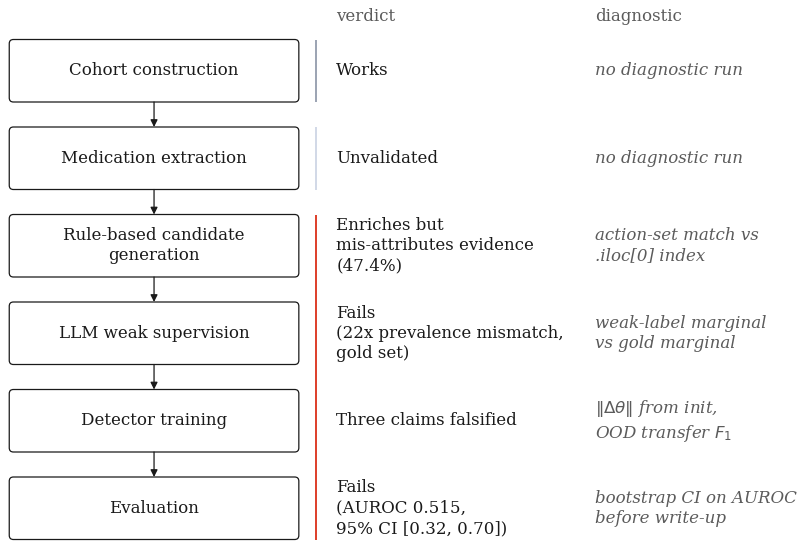

In [6]:
W, H = FIGW, 3.66
fig, ax = plt.subplots(figsize=(W, H))
canvas(fig)
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
ax.set_xlim(0, W * 72)
ax.set_ylim(0, H * 72)
ax.axis("off")

stages = ["Cohort construction", "Medication extraction",
          "Rule-based candidate\ngeneration", "LLM weak supervision",
          "Detector training", "Evaluation"]
# Sentence case, not the shouted capitals of the old filled badges: these
# are typographic labels now, and the rule beside them carries the verdict.
# No asterisks. They pointed at a note that had already been moved into the
# chapter caption, so on the page they were two marks referring to nothing.
verdicts = ["Works", "Unvalidated",
            f"Enriches but\nmis-attributes evidence\n({defect_rate*100:.1f}%)",
            f"Fails\n({ratio:.0f}x prevalence mismatch,\ngold set)",
            "Three claims falsified",
            f"Fails\n(AUROC {auroc:.3f},\n95% CI [{ci[0]:.2f}, {ci[1]:.2f}])"]
# Written out rather than left as a dash: the thesis bans en and em dashes,
# and a double hyphen renders on canvas as something a reader reads as one.
# The parameter-displacement diagnostic is set as mathematics because that is
# what it is; spelled out in underscored identifiers it read as a variable name
# someone had pasted in.
diagnostics = ["no diagnostic run", "no diagnostic run",
               "action-set match vs\n.iloc[0] index",
               "weak-label marginal\nvs gold marginal",
               r"$\|\Delta\theta\|$ from init," + "\n" + r"OOD transfer $F_1$",
               "bootstrap CI on AUROC\nbefore write-up"]

n = len(stages)
box_x, box_w, box_h, pitch = 3.0, 139.0, 30.0, 42.0
x_rule, x_verdict, x_diag = 150.0, 160.0, 284.0
y_top = 246.0
tops = [y_top - i * pitch for i in range(n)]
for i, (t, s, v, d) in enumerate(zip(tops, stages, verdicts, diagnostics)):
    ax.add_patch(FancyBboxPatch(
        (box_x, t - box_h), box_w, box_h,
        boxstyle="round,pad=0,rounding_size=2.0", mutation_aspect=1.0,
        linewidth=0.6, edgecolor=INK, facecolor="white"))
    ax.text(box_x + box_w / 2, t - box_h / 2, s, ha="center", va="center",
            fontsize=8.0, color=INK, linespacing=1.25)
    if i < n - 1:
        ax.annotate("", xy=(box_x + box_w / 2, t - box_h - pitch + box_h),
                    xytext=(box_x + box_w / 2, t - box_h),
                    arrowprops=dict(arrowstyle="-|>", color=INK, lw=0.6,
                                    mutation_scale=7, shrinkA=0, shrinkB=0))
    # The one stage a diagnostic actually passed is the only good news on this
    # canvas, and it was set in the same tone as the five failures beside it.
    # It takes the truth hue, at the darkened value 8 point type needs on
    # white. Everything else stays INK: the verdict rule beside the stages
    # already carries the failures in scarlet, and setting five failure
    # verdicts in red as well would put scarlet on most of the figure and
    # retire it as an accent.
    ax.text(x_verdict, t - box_h / 2, v, ha="left", va="center",
            fontsize=8.0, color=GREEN_T if v == "Works" else INK,
            linespacing=1.25)
    ax.text(x_diag, t - box_h / 2, d, ha="left", va="center", fontsize=8.0,
            style="italic", color=MUTE, linespacing=1.25)

ax.text(x_verdict, y_top + 7, "verdict", ha="left", va="bottom",
        fontsize=8.0, color=MUTE)
ax.text(x_diag, y_top + 7, "diagnostic", ha="left", va="bottom",
        fontsize=8.0, color=MUTE)

# The verdict rule, running beside the stages it judges. Three verdicts, three
# weights of rail, broken between them: grey against the one stage a diagnostic
# passed, pale against the one stage no diagnostic ever ran on, and scarlet
# against the four a diagnostic faulted. The first two used to share a single
# unbroken grey segment, which gave a stage that was never tested exactly the
# same mark as a stage that was tested and passed.
ax.plot([x_rule, x_rule], [tops[0], tops[0] - box_h],
        color=GREEN, lw=0.8, solid_capstyle="butt")
ax.plot([x_rule, x_rule], [tops[1], tops[1] - box_h],
        color=PALE, lw=0.8, solid_capstyle="butt")
ax.plot([x_rule, x_rule], [tops[2], tops[5] - box_h],
        color=SCARLET, lw=0.8, solid_capstyle="butt")

if SHOW_INFIGURE_TITLES: ax.text(W * 36, H * 72 - 4, "The pipeline as run, stage by stage",
        ha="center", va="top", fontsize=9.0)
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.02,
        "*Categorical only (not re-plotted with a number): CORRECTIONS.md C1/C2/C4 document that the\n"
        "authority-weight and rule-F1 claims did not survive re-audit; no committed result file in this\n"
        "repo carries the underlying numbers, so they are not re-typed here.",
        ha="center", fontsize=8.0, color=MUTE)

save_fig(fig, "fig-pipeline-status.pdf")
plt.show()


## Figure 2: `fig-intro-headline`

**Step 1. The data.** Read from `results/accord/diag/step0_1_join_and_calibration.json`, `results/accord/differential/exp1a_gold_error_rates_by_group.json`, `results/accord/diag/step2_signal_check.json`, `results/accord/stats/intervals.json`, `results/accord/reconciliation_c28.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [7]:
p_step01 = os.path.join(RESULTS_ACCORD, "diag", "step0_1_join_and_calibration.json")
d_step01 = json.load(open(p_step01))
xtab = d_step01["weak_confidence_is_degenerate"]["crosstab_label_x_confidence"]
weak_pos, weak_neg = xtab["0.95"]["contradiction"], xtab["1.0"]["not_contradiction"]
weak_n = weak_pos + weak_neg
weak_rate = weak_pos / weak_n

p_exp1a = os.path.join(RESULTS_ACCORD, "differential", "exp1a_gold_error_rates_by_group.json")
d_exp1a = json.load(open(p_exp1a))
lang = d_exp1a["language_group3"]
pred_pos = sum(g["TP"] + g["FP"] for g in lang)
pred_n = sum(g["n"] for g in lang)
pred_rate = pred_pos / pred_n

p_step2 = os.path.join(RESULTS_ACCORD, "diag", "step2_signal_check.json")
d_step2 = json.load(open(p_step2))
d299 = d_step2["contra_prob_vs_pharm_label__ambiguous_as_negative_n299"]
pharm_pos, pharm_n = d299["n_pos"], d299["n"]
pharm_rate = pharm_pos / pharm_n

p_intervals = os.path.join(RESULTS_ACCORD, "stats", "intervals.json")
d_intervals = json.load(open(p_intervals))
mcc = d_intervals["E2_mcc_intervals"]
order = ["gpt4o_zeroshot", "gpt4o_fewshot", "accord_binary_at_0.5_253core", "llama_baseline"]
labels = ["GPT-4o zero-shot", "GPT-4o few-shot", "ACCORD (contam.)", "Llama 3 8B"]

p_c28 = os.path.join(RESULTS_ACCORD, "reconciliation_c28.json")
d_c28 = json.load(open(p_c28))
accord_pred = d_c28["a_what_each_number_counts"]["278"]
weak_marginal = d_c28["a_what_each_number_counts"]["261"]

def wilson_ci(k, n, z=1.959963984540054):
    """Wilson score interval for a binomial proportion; closed-form, deterministic."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z ** 2 / n
    centre = p + z ** 2 / (2 * n)
    adj = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2))
    # Clamped to [0, 1] and to the estimate itself, identically to the helper in
    # the setup cell: at k = 0 the exact lower bound is 0 and the arithmetic
    # lands a few parts in 10^18 either side of it.
    lo = min(p, max(0.0, (centre - adj) / denom))
    hi = max(p, min(1.0, (centre + adj) / denom))
    return (lo, hi)

print("fig-intro-headline: values plotted")
print(f"  weak-label positive rate, train pool     : {weak_pos}/{weak_n} = {weak_rate:.4f}")
print(f"  left-panel middle bar (exp1a TP+FP sum)  : {pred_pos}/{pred_n} = {pred_rate:.4f}  (the weak labeller on the gold set, NOT ACCORD)")
print(f"  pharmacist true rate, gold set (n=299)   : {pharm_pos}/{pharm_n} = {pharm_rate:.4f}")
for k in order:
    v = mcc[k]
    print(f"  MCC {k:32s}: {v['mcc']:+.4f}  95% CI [{v['ci95'][0]:+.4f}, {v['ci95'][1]:+.4f}]")
print(f"  reconciliation_c28: ACCORD predicted-positive = {accord_pred['value']}/{accord_pred['denominator']}"
      f"  (accord_pred == 'contradiction')")
print(f"  reconciliation_c28: weak-labeller marginal    = {weak_marginal['value']}/{weak_marginal['denominator']}"
      f"  (weak_label == 'contradiction', matches the {pred_pos}/{pred_n} bar above)")

# The right panel gets the wider share: its four category labels need room
# side by side, while the left panel's y labels live outside its axes.

fig-intro-headline: values plotted
  weak-label positive rate, train pool     : 1425/1679 = 0.8487
  left-panel middle bar (exp1a TP+FP sum)  : 261/299 = 0.8729  (the weak labeller on the gold set, NOT ACCORD)
  pharmacist true rate, gold set (n=299)   : 12/299 = 0.0401
  MCC gpt4o_zeroshot                  : +0.1089  95% CI [-0.0319, +0.2484]
  MCC gpt4o_fewshot                   : +0.0117  95% CI [-0.1120, +0.1319]
  MCC accord_binary_at_0.5_253core    : -0.0070  95% CI [-0.1626, +0.0753]
  MCC llama_baseline                  : -0.0436  95% CI [-0.2337, +0.0563]
  reconciliation_c28: ACCORD predicted-positive = 278/299  (accord_pred == 'contradiction')
  reconciliation_c28: weak-labeller marginal    = 261/299  (weak_label == 'contradiction', matches the 261/299 bar above)


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-intro-headline.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-intro-headline.pdf


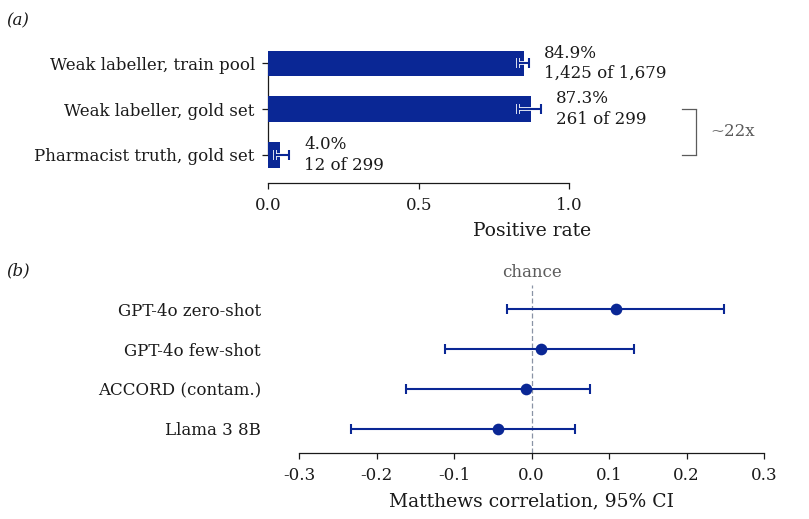

In [8]:
# The graphical abstract of the thesis: two stacked panels sharing one label
# gutter and one measure, both read left to right along a common grammar.
# (a) is a rate of a whole, so bars; (b) is an estimate, so dots with
# intervals. Stacked rather than side by side because at this measure two
# label gutters side by side leave no room for either panel's data.
fig, (axL, axR) = plt.subplots(2, 1, figsize=(FIGW, 3.42),
                               gridspec_kw={"height_ratios": [74, 84]})
canvas(fig)
fig.subplots_adjust(left=0.330, right=0.985, top=0.938, bottom=0.122, hspace=0.640)

# Middle bar: 261/299 is the weak labeller's marginal on the gold set, not
# ACCORD's own predicted-positive count (that is 278/299). reconciliation_c28.json
# exists to settle exactly this, and the bar was previously mislabelled ACCORD.
# The denominators live in the tick labels now, out of the plot area.
bars = [("Weak labeller, train pool", weak_pos, weak_n, wilson_ci(weak_pos, weak_n)),
        ("Weak labeller, gold set", pred_pos, pred_n, wilson_ci(pred_pos, pred_n)),
        ("Pharmacist truth, gold set", pharm_pos, pharm_n, wilson_ci(pharm_pos, pharm_n))]
ypos = np.arange(len(bars))[::-1]
rates = [b[1] / b[2] for b in bars]
los = [b[3][0] for b in bars]
his = [b[3][1] for b in bars]
errs = [[r - lo for r, lo in zip(rates, los)], [hi - r for r, hi in zip(rates, his)]]
# The interval is the bar's own, so it is the bar's own colour. Black caps on
# a blue bar read as a second series laid over the first. But a blue interval
# on a blue bar loses its lower half inside the fill, so the interval reads
# one-sided and the bar reads as if it were exact: the interval is therefore
# cased in white, a slightly wider white stroke drawn under it, so both halves
# read against the fill and against the paper.
# Two hues, because there are two things here and not three: the same weak
# labeller measured on two different pools, and the pharmacist against whom it
# is measured. Drawing all three in one colour asked the reader to find the
# instrument-versus-truth split in the row labels alone, which is the split the
# whole thesis turns on. The weak labeller is Llama 3 8B, so it carries Llama's
# hue here and on every other figure; the pharmacist carries the truth hue.
bar_hues = [PURPLE, PURPLE, GREEN]
axL.barh(ypos, rates, color=bar_hues, linewidth=0, height=0.55, zorder=3)
axL.errorbar(rates, ypos, xerr=errs, fmt="none", ecolor="white",
             elinewidth=1.8, capthick=1.8, capsize=ERRBAR["capsize"], zorder=4)
for y_, r_, elo_, ehi_, hue_ in zip(ypos, rates, errs[0], errs[1], bar_hues):
    axL.errorbar([r_], [y_], xerr=[[elo_], [ehi_]], fmt="none", ecolor=hue_,
                 zorder=5, **ERRBAR)
# One value label per bar, all in the same place: clear of the upper interval
# cap, rate above and count below, so no label can reach the bracket.
for y, b, r, hi in zip(ypos, bars, rates, his):
    axL.text(hi + 0.05, y, f"{r*100:.1f}%\n{b[1]:,} of {b[2]:,}", va="center",
             ha="left", fontsize=8.0, color=INK, linespacing=1.25)
axL.set_yticks(ypos)
axL.set_yticklabels([b[0] for b in bars], fontsize=8.0, linespacing=1.3)
axL.set_xlim(0, 1.75)
axL.set_ylim(-0.62, 2.62)
axL.set_xticks([0, 0.5, 1.0])
axL.set_xlabel("Positive rate")
# The spines are cut back to the range they measure, so neither axis line
# runs on into the annotation gutter.
lean(axL, xbounds=(0, 1.0), ybounds=(0, 2))
if SHOW_INFIGURE_TITLES: axL.set_title(f"Marginal, weak label against truth ({weak_rate/pharm_rate:.0f}x)", fontsize=8.5)
# The bracket compares the two bars measured on the same 299-pair gold set.
# It used to span the training-pool bar and the gold-set bar, which have
# different denominators.
gold_ratio = (pred_pos / pred_n) / (pharm_pos / pharm_n)
x_bracket = 1.42
axL.plot([x_bracket] * 2, [ypos[2], ypos[1]], color=MUTE, lw=0.6,
         solid_capstyle="butt", zorder=4)
for y in (ypos[1], ypos[2]):
    axL.plot([x_bracket, x_bracket - 0.045], [y, y], color=MUTE, lw=0.6, zorder=4)
axL.text(x_bracket + 0.05, (ypos[1] + ypos[2]) / 2, f"~{gold_ratio:.0f}x",
         va="center", ha="left", fontsize=8.0, color=MUTE)

# An MCC is an estimate, not a quantity of anything, so it is drawn as a dot
# with its interval, in the same grammar as every other estimate in this
# thesis. Rows, not columns, so that the eye reads the four intervals
# against one vertical chance line.
ys = np.arange(len(order))[::-1]
vals = [mcc[k]["mcc"] for k in order]
ci_lo = [mcc[k]["ci95"][0] for k in order]
ci_hi = [mcc[k]["ci95"][1] for k in order]
err = [[v - lo for v, lo in zip(vals, ci_lo)], [hi - v for v, hi in zip(vals, ci_hi)]]
axR.axvline(0, **CHANCE_STYLE)
# Four systems, four hues, from the map: the two GPT-4o prompting conditions
# take one hue at two values because they are one model, ACCORD takes its own,
# and Llama 3 8B takes the hue the weak-labeller bars in (a) carry, because the
# weak labeller is that same model in another role.
row_hues = [BLUE2, SKY, ORANGE, PURPLE]
for v_, y_, lo_, hi_, hue_ in zip(vals, ys, err[0], err[1], row_hues):
    axR.errorbar([v_], [y_], xerr=[[lo_], [hi_]], fmt="o", color=hue_, zorder=3,
                 **ERRBAR, **DOT)
axR.set_yticks(ys)
axR.set_yticklabels(labels, fontsize=8.0)
axR.set_ylim(-0.62, 3.62)
# Ticks and spine both run past the widest cap (the zero-shot interval reaches
# 0.2484), so no interval ends beyond the scale it is read on.
axR.set_xlim(-0.34, 0.34)
axR.set_xticks([-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3])
axR.set_xlabel("Matthews correlation, 95% CI")
if SHOW_INFIGURE_TITLES: axR.set_title("MCC, 95% CI, n=253", fontsize=8.5)
# Sits at the top of the reference line it names, clear of every interval.
axR.text(0.0, 3.72, "chance", fontsize=8.0, color=MUTE, va="bottom",
         ha="center", clip_on=False)
# ACCORD is not accented here. This panel's claim is that all four intervals
# contain zero, which is a property of the column and not of any one row, so
# nothing in it takes the accent.
lean(axR, xbounds=(-0.3, 0.3))
axR.spines["left"].set_visible(False)
axR.tick_params(axis="y", length=0)

for ax, tag in ((axL, "(a)"), (axR, "(b)")):
    p = ax.get_position()
    fig.text(0.004, p.y1 + 0.010, tag, ha="left", va="bottom",
             fontsize=8.0, style="italic", color=INK)

if SHOW_INFIGURE_TITLES: fig.suptitle("The number that determines the rest of the thesis", fontsize=9.0, y=0.97)
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.02,
        "Left-panel middle bar (weak labeller gold-set marginal): 261/299, summed from per-group counts in\n"
        "exp1a_gold_error_rates_by_group.json. CORRECTIONS.md C28 flags an unresolved 17-row discrepancy against a\n"
        "raw-file count of 278/299 in a file not committed to this repo; the value shown is the one reconstructable here.",
        ha="center", fontsize=8.0, color=MUTE)

save_fig(fig, "fig-intro-headline.pdf")
plt.show()


## Figure 3: `fig-cohort-flow`

**Step 1. The data.** Read from `results/accord/stats/cohort_icd_counts.json`, `results/accord/generality/transfer_results_correct.json`, `results/accord/diag/step2_signal_check.json`, `results/accord/VERIFIED_FACTS.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [9]:
p_icd = os.path.join(RESULTS_ACCORD, "stats", "cohort_icd_counts.json")
hf = json.load(open(p_icd))["heart_failure"]

p_transfer = os.path.join(RESULTS_ACCORD, "generality", "transfer_results_correct.json")
n_candidates = json.load(open(p_transfer))["hf_reference"]["n_candidates"]

p_step2 = os.path.join(RESULTS_ACCORD, "diag", "step2_signal_check.json")
d_step2 = json.load(open(p_step2))
d299 = d_step2["contra_prob_vs_pharm_label__ambiguous_as_negative_n299"]
d253 = d_step2["contra_prob_vs_pharm_label__ambiguous_excluded_n253"]
d_amb = d_step2["contra_prob_vs_pharm_label__ambiguous_as_positive_n299"]
# The ambiguous count is not stored on its own line. It is the difference
# between the two positive counts recorded in the same file on the same 299
# rows, ambiguous counted positive against ambiguous counted negative, which is
# the same subtraction the prevalence figure performs.
n_ambiguous = d_amb["n_pos"] - d299["n_pos"]

# Four stages have no primary artifact inside this repository: their upstream
# summaries live outside it under the data agreement. Their values are read from
# the thesis register, which is committed here and records the artifact each one
# came from.
p_facts = os.path.join(RESULTS_ACCORD, "VERIFIED_FACTS.json")
facts = json.load(open(p_facts))
fact = lambda key: facts[key]["value"]

n_both_roles = fact("cohort_chain.has_both_roles")
n_pairs = fact("cohort_chain.valid_admissions_both_selected")
n_note_rows = fact("cohort_chain.total_note_pair_rows")
n_mentions = fact("extraction.medication_extraction.total_mentions")
n_classified = fact("extraction.medication_extraction.classified_mentions")
n_unclassified = fact("extraction.medication_extraction.unclassified_derived")
n_drawn = fact("extraction.annotation_sample.total_sampled")

print("fig-cohort-flow: values plotted")
print(f"  ICD prefix admissions      {hf['pre_los']:>8,}")
print(f"  removed by length of stay  {hf['removed']:>8,}")
print(f"  after length of stay       {hf['post_los']:>8,}")
print(f"  both note roles present    {n_both_roles:>8,}")
print(f"  note pairs selected        {n_pairs:>8,}   note rows {n_note_rows:,}")
print(f"  medication mentions        {n_mentions:>8,}")
print(f"  no action class            {n_unclassified:>8,}")
print(f"  action classified          {n_classified:>8,}")
print(f"  candidates after prefilter {n_candidates:>8,}")
print(f"  annotated pairs            {d299['n']:>8,}   of {n_drawn:,} drawn")
print(f"  coded ambiguous            {n_ambiguous:>8,}")
print(f"  non-ambiguous core         {d253['n']:>8,}   positives {d253['n_pos']}")


fig-cohort-flow: values plotted
  ICD prefix admissions        13,608
  removed by length of stay        11
  after length of stay         13,597
  both note roles present       9,820
  note pairs selected           9,783   note rows 19,566
  medication mentions         219,683
  no action class             131,347
  action classified            88,336
  candidates after prefilter    1,978
  annotated pairs                 299   of 300 drawn
  coded ambiguous                  46
  non-ambiguous core              253   positives 12


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-cohort-flow.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-cohort-flow.pdf


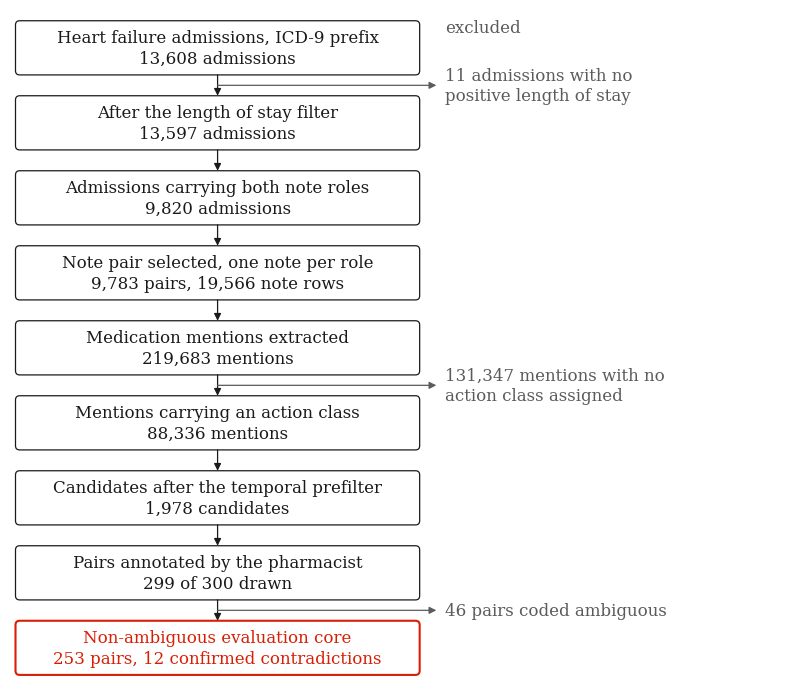

In [10]:
# Same point grid as the other schematics in this set: the axes span exactly the
# figure and one data unit is one typographic point, so the nine boxes are
# identical by construction and every row sits on one baseline.
W, H = FIGW, 4.62
fig, ax = plt.subplots(figsize=(W, H))
canvas(fig)
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
ax.set_xlim(0, W * 72)
ax.set_ylim(0, H * 72)
ax.axis("off")

# (stage name, count line, exclusion below this stage or None)
stages = [
    ("Heart failure admissions, ICD-9 prefix",
     f"{hf['pre_los']:,} admissions",
     f"{hf['removed']:,} admissions with no\npositive length of stay"),
    ("After the length of stay filter",
     f"{hf['post_los']:,} admissions", None),
    ("Admissions carrying both note roles",
     f"{n_both_roles:,} admissions", None),
    ("Note pair selected, one note per role",
     f"{n_pairs:,} pairs, {n_note_rows:,} note rows", None),
    ("Medication mentions extracted",
     f"{n_mentions:,} mentions",
     f"{n_unclassified:,} mentions with no\naction class assigned"),
    ("Mentions carrying an action class",
     f"{n_classified:,} mentions", None),
    ("Candidates after the temporal prefilter",
     f"{n_candidates:,} candidates", None),
    ("Pairs annotated by the pharmacist",
     f"{d299['n']} of {n_drawn} drawn",
     f"{n_ambiguous} pairs coded ambiguous"),
    ("Non-ambiguous evaluation core",
     f"{d253['n']} pairs, {d253['n_pos']} confirmed contradictions", None),
]

box_x, box_w, box_h, pitch = 6.0, 194.0, 26.0, 36.0
x_excl = 212.0
y_top = H * 72 - 9.0
tops = [y_top - i * pitch for i in range(len(stages))]
x_stem = box_x + box_w / 2

for i, (t, (name, count, excl)) in enumerate(zip(tops, stages)):
    # The last box is the one mark that carries what this figure asserts: the
    # evaluated set the whole path ends at, and the twelve confirmed
    # contradictions inside it. Scarlet stroke and scarlet text, the same
    # treatment the exemplar schematic gives its one wrong slot, rather than a
    # filled block.
    last = i == len(stages) - 1
    edge = SCARLET if last else INK
    ax.add_patch(FancyBboxPatch(
        (box_x, t - box_h), box_w, box_h,
        boxstyle="round,pad=0,rounding_size=2.0", mutation_aspect=1.0,
        linewidth=1.0 if last else 0.6, edgecolor=edge, facecolor="white"))
    ax.text(box_x + box_w / 2, t - box_h / 2, f"{name}\n{count}",
            ha="center", va="center", fontsize=8.0, color=edge,
            linespacing=1.35)
    if not last:
        ax.annotate("", xy=(x_stem, t - pitch),
                    xytext=(x_stem, t - box_h),
                    arrowprops=dict(arrowstyle="-|>", color=INK, lw=0.6,
                                    mutation_scale=7, shrinkA=0, shrinkB=0))
    if excl is not None:
        # A CONSORT exclusion leaves the trunk in the gap between two stages and
        # runs right, so it reads as taken out between them rather than as a
        # second thing the stage produced.
        y_gap = t - box_h - (pitch - box_h) / 2
        ax.annotate("", xy=(x_excl - 4.0, y_gap), xytext=(x_stem, y_gap),
                    arrowprops=dict(arrowstyle="-|>", color=MUTE, lw=0.6,
                                    mutation_scale=7, shrinkA=0, shrinkB=0))
        ax.text(x_excl, y_gap, excl, ha="left", va="center", fontsize=8.0,
                color=MUTE, linespacing=1.25)

ax.text(x_excl, y_top + 1.0, "excluded", ha="left", va="top", fontsize=8.0,
        color=MUTE)

save_fig(fig, "fig-cohort-flow.pdf")
plt.show()


## Figure 4: `fig-exemplar`

**Step 1. The data.** Read from `results/accord/exemplar/exemplar_correctness_recomputed.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [11]:
p_exemplar = os.path.join(RESULTS_ACCORD, "exemplar", "exemplar_correctness_recomputed.json")
d_exemplar = json.load(open(p_exemplar))
ex = d_exemplar["rule_1_2_pooled"]
defect_rate = ex["n_wrong"] / ex["n_resolved"]

print("fig-exemplar: values plotted")
print(f"  rule_1_2_pooled: n_wrong={ex['n_wrong']}, n_resolved={ex['n_resolved']}, defect_rate={defect_rate:.4f}")

# Widened and re-anchored. Previously the trigger caption ran into the
# "Discharge summary" heading, both leader arrows crossed a slot box and struck
# through its label, the right-hand annotations ran off the axes, and the summary
# text was wider than the box drawn around it.

fig-exemplar: values plotted
  rule_1_2_pooled: n_wrong=65, n_resolved=137, defect_rate=0.4745


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-exemplar.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-exemplar.pdf


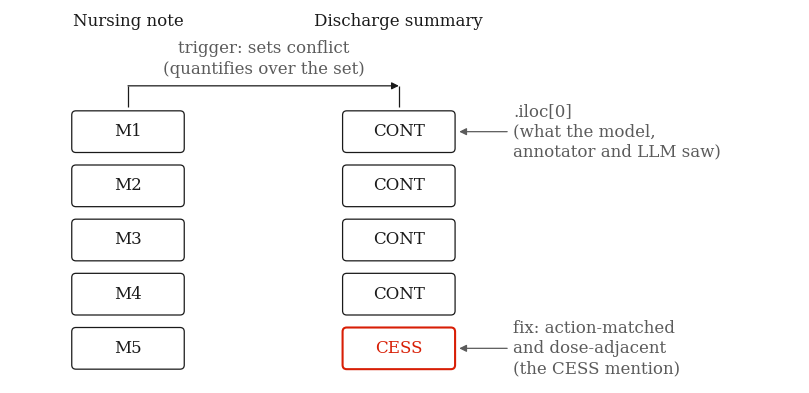

In [12]:
# The canvas is shorter than it was by exactly the two lines of summary
# sentence that have moved to the caption.
W, H = FIGW, 2.58
fig, ax = plt.subplots(figsize=(W, H))
canvas(fig)
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
ax.set_xlim(0, W * 72)
ax.set_ylim(0, H * 72)
ax.axis("off")

# Two columns of abstract mention slots (no clinical text).
col_x = {"Nursing note": 60.0, "Discharge summary": 190.0}
box_w, box_h, pitch = 54.0, 20.0, 26.0
rows_y = [124.0 - i * pitch for i in range(5)]
for label, x in col_x.items():
    ax.text(x, 177.0, label, ha="center", va="center", fontsize=8.0,
            color=INK)

nurse_tags = ["M1", "M2", "M3", "M4", "M5"]
disch_tags = ["CONT", "CONT", "CONT", "CONT", "CESS"]
for i, y in enumerate(rows_y):
    for col, tags in ((col_x["Nursing note"], nurse_tags),
                      (col_x["Discharge summary"], disch_tags)):
        # The one highlighted slot is a scarlet stroke and scarlet text, not
        # a filled block: the accent marks it without shouting.
        hit = (col == col_x["Discharge summary"] and i == 4)
        edge = SCARLET if hit else INK
        ax.add_patch(FancyBboxPatch(
            (col - box_w / 2, y - box_h / 2), box_w, box_h,
            boxstyle="round,pad=0,rounding_size=2.0", mutation_aspect=1.0,
            linewidth=1.0 if hit else 0.6, edgecolor=edge, facecolor="white"))
        ax.text(col, y, tags[i], ha="center", va="center", fontsize=8.0,
                color=edge)

# The trigger arrow spans the two columns it relates, from the centre of the
# M column to the centre of the CONT column, dropping a short stem at each end
# onto the column it names. It used to float in the gutter between them,
# touching neither, which left the reader to guess what was being related to
# what.
x_l, x_r = col_x["Nursing note"], col_x["Discharge summary"]
y_arrow, y_stem = 146.0, 136.0
for x in (x_l, x_r):
    ax.plot([x, x], [y_stem, y_arrow], color=INK, lw=0.6,
            solid_capstyle="butt", zorder=1)
ax.annotate("", xy=(x_r, y_arrow), xytext=(x_l, y_arrow),
            arrowprops=dict(arrowstyle="-|>", color=INK, lw=0.6,
                            mutation_scale=7, shrinkA=0, shrinkB=0))
ax.text((x_l + x_r) / 2, y_arrow + 4.0,
        "trigger: sets conflict\n(quantifies over the set)", ha="center",
        va="bottom", fontsize=8.0, color=MUTE, linespacing=1.25)

# Leaders: one weight, one length, attached to the right edge of the slot they
# name, so neither crosses a box. Both notes are annotation, so both are drawn
# in the secondary text tone with their arrows: the scarlet CESS slot is the
# one accent on this canvas and carries the finding by itself. A scarlet note
# beside a scarlet box put the accent on the canvas twice and made the sentence
# compete with the thing it points at.
x_tip = col_x["Discharge summary"] + box_w / 2 + 2
x_note = x_tip + 26
for y, note, colour in ((rows_y[0], ".iloc[0]\n(what the model,\nannotator and LLM saw)", MUTE),
                        (rows_y[4], "fix: action-matched\nand dose-adjacent\n(the CESS mention)", MUTE)):
    ax.annotate("", xy=(x_tip, y), xytext=(x_note - 3, y),
                arrowprops=dict(arrowstyle="-|>", color=colour, lw=0.6,
                                mutation_scale=7, shrinkA=0, shrinkB=0))
    ax.text(x_note, y, note, va="center", ha="left", fontsize=8.0,
            color=colour, linespacing=1.25)

# The measured rate is gone from the canvas and lives in the caption. This
# panel is a schematic of one candidate: five slots, one of them wrong. Welding
# a population rate to a picture of a single case invited the reader to take the
# picture as the estimate of the rate, which it is not, and the rate itself is
# reported two ways in the chapter.

save_fig(fig, "fig-exemplar.pdf")
plt.show()


## Figure 5: `fig-prevalence-response`

**Step 1. The data.** Read from `results/accord/prevalence_replication/sweep_results.json`, `results/accord/diag/step0_1_join_and_calibration.json`, `results/accord/diag/step2_signal_check.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [13]:
p_sweep = os.path.join(RESULTS_ACCORD, "prevalence_replication", "sweep_results.json")
d_sweep = json.load(open(p_sweep))
models = d_sweep["models"]
prompts = ["A_bare", "B_baserate_abstain"]
# The second row label is wrapped: on one line it ran the full height of its
# panel and collided with the row above it.
prompt_label = {"A_bare": "bare prompt", "B_baserate_abstain": "base rate stated,\nabstention allowed"}

# The "clinical" comparison point: same weak-label-vs-pharmacist shift as figures 1 and 2,
# recomputed here from the same two diagnostic files (not typed in).
p_step01 = os.path.join(RESULTS_ACCORD, "diag", "step0_1_join_and_calibration.json")
d_step01 = json.load(open(p_step01))
xtab = d_step01["weak_confidence_is_degenerate"]["crosstab_label_x_confidence"]
weak_pos, weak_neg = xtab["0.95"]["contradiction"], xtab["1.0"]["not_contradiction"]
clinical_y = weak_pos / (weak_pos + weak_neg)

p_step2 = os.path.join(RESULTS_ACCORD, "diag", "step2_signal_check.json")
d_step2 = json.load(open(p_step2))
clinical_x = d_step2["contra_prob_vs_pharm_label__ambiguous_as_negative_n299"]["base_rate"]

print("fig-prevalence-response: values plotted")
print(f"  models: {models}")
print(f"  clinical marker (true prevalence, labeller positive rate): ({clinical_x:.4f}, {clinical_y:.4f})")
for pr in prompts:
    for m in models:
        pts = {p: d_sweep["results"][m][pr].get(p) for p in ["0.02", "0.05", "0.1", "0.25"]}
        rates = {p: (e["positive_rate_of_decided"] if e else None) for p, e in pts.items()}
        print(f"  {m:14s} / {prompt_label[pr]:38s}: {rates}")

fig-prevalence-response: values plotted
  models: ['llama3:8b', 'granite3.3:8b', 'qwen3:8b']
  clinical marker (true prevalence, labeller positive rate): (0.0401, 0.8487)
  llama3:8b      / bare prompt                           : {'0.02': 0.07, '0.05': 0.17, '0.1': 0.06, '0.25': 0.12}
  granite3.3:8b  / bare prompt                           : {'0.02': 0.05, '0.05': 0.07, '0.1': 0.1, '0.25': 0.16}
  qwen3:8b       / bare prompt                           : {'0.02': 0.02, '0.05': 0.03, '0.1': 0.05, '0.25': 0.09}
  llama3:8b      / base rate stated,
abstention allowed  : {'0.02': 0.0410958904109589, '0.05': 0.10975609756097561, '0.1': 0.05405405405405406, '0.25': 0.07352941176470588}
  granite3.3:8b  / base rate stated,
abstention allowed  : {'0.02': 0.030612244897959183, '0.05': 0.04, '0.1': 0.09, '0.25': 0.17}
  qwen3:8b       / base rate stated,
abstention allowed  : {'0.02': 0.0, '0.05': 0.0, '0.1': 0.025, '0.25': 0.02666666666666667}


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-prevalence-response.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-prevalence-response.pdf


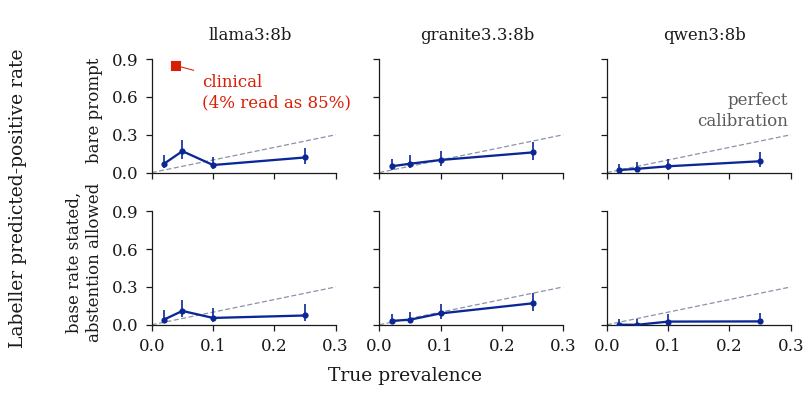

In [14]:
# One hue per labeller, held down both rows of its column, so a column reads as
# one model under two prompts rather than as six unrelated panels. llama3:8b is
# the thesis's own production weak labeller, so it carries the same hue here
# that the weak-labeller bars and the Llama 3 8B baseline carry elsewhere.
MODEL_HUE = {"llama3:8b": PURPLE, "granite3.3:8b": GREEN, "qwen3:8b": BLUE2}
MODEL_HUE_T = {"llama3:8b": PURPLE_T, "granite3.3:8b": GREEN_T, "qwen3:8b": BLUE2_T}
fig, axes = plt.subplots(2, 3, figsize=(FIGW, 2.60), sharex=True, sharey=True)
canvas(fig)
fig.subplots_adjust(left=0.185, right=0.995, top=0.885, bottom=0.175,
                    wspace=0.16, hspace=0.22)
for r, pr in enumerate(prompts):
    for c, m in enumerate(models):
        ax = axes[r, c]
        xs, ys, lo, hi = [], [], [], []
        for p in ["0.02", "0.05", "0.1", "0.25"]:
            e = d_sweep["results"][m][pr].get(p)
            if not e:
                continue
            xs.append(float(p)); ys.append(e["positive_rate_of_decided"])
            # The sweep commits both counts behind every rate, so the interval
            # is a closed-form Wilson score interval on those counts: no
            # resampling, no simulation, nothing invented. A rate printed on
            # 100 decisions without one invites the reader to read a two-point
            # wobble as a response to prevalence.
            a, b = wilson_ci(e["n_contradiction"], e["n_decided"])
            lo.append(a); hi.append(b)
        hue = MODEL_HUE[m]
        ax.plot([0, .30], [0, .30], **CHANCE_STYLE)
        ax.errorbar(xs, ys, yerr=[[y - a for y, a in zip(ys, lo)],
                                  [b - y for y, b in zip(ys, hi)]],
                    fmt="-o", color=hue, ms=3.0, lw=1.1, zorder=3,
                    markeredgewidth=0, ecolor=hue, elinewidth=0.8,
                    capthick=0.8, capsize=2.0)
        # The clinical operating point is the claim this whole grid is drawn
        # against, so it is the one accented mark, and it appears once. Six
        # copies of one anchor read as six separate findings and put a scarlet
        # square in every panel.
        if r == 0 and c == 0:
            ax.plot([clinical_x], [clinical_y], "s", color=SCARLET, ms=3.6, zorder=4)
            ax.annotate(f"clinical\n({clinical_x * 100:.0f}% read as {clinical_y * 100:.0f}%)",
                        (clinical_x, clinical_y), xytext=(0.082, 0.52),
                        fontsize=8.0, color=SCARLET, linespacing=1.25,
                        arrowprops=dict(arrowstyle="-", lw=.5, color=SCARLET))
        if r == 0 and c == 2:
            ax.text(0.295, 0.34, "perfect\ncalibration", fontsize=8.0, color=MUTE,
                    ha="right", va="bottom", linespacing=1.25)
        # Bounds and ticks run past every mark and every cap, so nothing on the
        # grid hangs off the end of the scale it is measured on.
        ax.set_xlim(0, .32); ax.set_ylim(0, .99)
        ax.set_xticks([0, 0.1, 0.2, 0.3]); ax.set_yticks([0, 0.3, 0.6, 0.9])
        # Panel heading, not a figure title: it names which labeller this column
        # is, and it is set in that labeller's own hue, darkened to the value 8
        # point type needs on white. That heading is also what carries the
        # column apart in a greyscale print, where three of these hues are the
        # same grey.
        if r == 0:
            ax.set_title(m, fontsize=8.0, pad=4, color=MODEL_HUE_T[m])
        if c == 0: ax.set_ylabel(prompt_label[pr], fontsize=8.0, linespacing=1.3)
        ax.tick_params(labelsize=8)
        lean(ax, xbounds=(0, 0.30), ybounds=(0, 0.9))
fig.supxlabel("True prevalence", fontsize=9.0, y=0.020)
fig.supylabel("Labeller predicted-positive rate", fontsize=9.0, x=0.008)
if SHOW_INFIGURE_TITLES: fig.suptitle("The labeller under-responds to prevalence, but nowhere near the clinical shift",
             fontsize=9.5, x=0.02, ha="left", y=0.99)

save_fig(fig, "fig-prevalence-response.pdf")
plt.show()


## Figure 6: `fig-falsification`

**Step 1. The data.** Read from `results/accord/decontam/accord_v2_decontam_gold_aggregate.json`, `results/accord/generality/transfer_results_correct.json`, `results/accord/number_provenance_audit.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [15]:
p_agg = os.path.join(RESULTS_ACCORD, "decontam", "accord_v2_decontam_gold_aggregate.json")
d_agg = json.load(open(p_agg))
aN, aD = d_agg["aggregate"]["alpha_n"]["mean"], d_agg["aggregate"]["alpha_d"]["mean"]
sN, sD = d_agg["aggregate"]["alpha_n"]["std"], d_agg["aggregate"]["alpha_d"]["std"]

p_transfer = os.path.join(RESULTS_ACCORD, "generality", "transfer_results_correct.json")
d_transfer = json.load(open(p_transfer))
f1 = [d_transfer["hf_reference"]["rule_type_f1"], d_transfer["sepsis"]["rule_type_f1"], d_transfer["aki"]["rule_type_f1"]]
cohort_labels = ["HF\n(in domain)", "sepsis", "AKI"]
n_cand = [d_transfer["hf_reference"]["n_candidates"], d_transfer["sepsis"]["n_candidates"],
          d_transfer["aki"]["n_candidates"]]
# The three seeds behind each mean, read from the same file the means come from.
seeds = sorted(d_agg["per_seed"])
seed_N = [d_agg["per_seed"][s]["authority_scale"]["alpha_nursing"] for s in seeds]
seed_D = [d_agg["per_seed"][s]["authority_scale"]["alpha_discharge"] for s in seeds]

p_audit = os.path.join(RESULTS_ACCORD, "number_provenance_audit.json")
d_audit = json.load(open(p_audit))
claim = next(r for r in d_audit["records"] if "45.2" in r["claim"])
# The 45.2% held-out rule-accuracy reference line has been REMOVED from this
# figure: 0.4515 appears in no result file anywhere on disk, only in figure code
# and in the audit record printed below, which flags it as untraceable.

print("fig-falsification: values plotted")
print(f"  alpha_N (nursing authority scale), 3-seed mean +/- std : {aN:.4f} +/- {sN:.4f}")
print(f"  alpha_D (discharge authority scale), 3-seed mean +/- std: {aD:.4f} +/- {sD:.4f}")
for lab, v, nc in zip(cohort_labels, f1, n_cand):
    print(f"  rule-type F1, {lab.replace(chr(10), ' '):16s}: {v:.4f}  (n={nc})")
print(f"  alpha_N per seed: {['%.4f' % v for v in seed_N]}")
print(f"  alpha_D per seed: {['%.4f' % v for v in seed_D]}")
print("  alpha initialisation 0.5 / 1.0: a stated design constant, not a measurement;")
print("    it is in no result file, and the figure legend now says so.")
print("  NOT plotted (removed): held-out rule-prediction accuracy 0.4515")
print(f"  number_provenance_audit.json claim record: {claim}")

fig-falsification: values plotted
  alpha_N (nursing authority scale), 3-seed mean +/- std : 0.5076 +/- 0.0006
  alpha_D (discharge authority scale), 3-seed mean +/- std: 1.0038 +/- 0.0010
  rule-type F1, HF (in domain)  : 0.9603  (n=1978)
  rule-type F1, sepsis          : 0.0654  (n=775)
  rule-type F1, AKI             : 0.0595  (n=1983)
  alpha_N per seed: ['0.5070', '0.5074', '0.5084']
  alpha_D per seed: ['1.0024', '1.0042', '1.0047']
  alpha initialisation 0.5 / 1.0: a stated design constant, not a measurement;
    it is in no result file, and the figure legend now says so.
  NOT plotted (removed): held-out rule-prediction accuracy 0.4515
  number_provenance_audit.json claim record: {'claim': '45.2% held-out rule-prediction accuracy (recomputes to 0.4515)', 'tex_location': 'ch6:291', 'artifact': 'gold-standard CSV per ch6 caption', 'artifact_exists': False, 'reported': 0.452, 'recomputed': None, 'verdict': 'UNTRACEABLE', 'blast_radius': 'body', 'note': "Caption asserts it 'recompu

**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-falsification.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-falsification.pdf


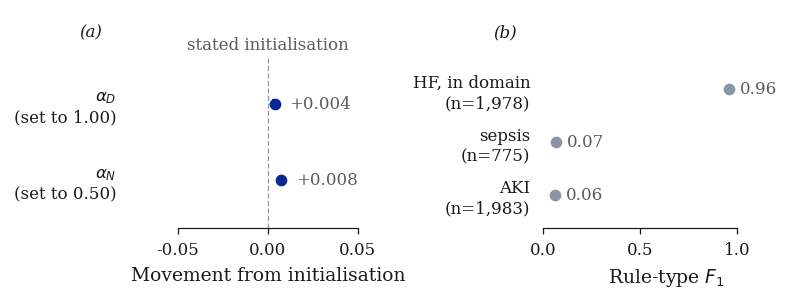

In [16]:
fig, (a, b) = plt.subplots(1, 2, figsize=(FIGW, 1.95),
                           gridspec_kw={"width_ratios": [1.12, 1.0]})
canvas(fig)
fig.subplots_adjust(left=0.150, right=0.985, top=0.815, bottom=0.230, wspace=0.46)

# (a) Drawn as a displacement, so the geometry is the claim. The quantity on the
# axis is how far each parameter moved from the value it was set to, and the
# reference is a line at no movement at all. A parameter reported as learned
# that lands on that line has not been learned. The earlier version plotted the
# parameter itself against a grey tick for the initialisation, which put the
# whole claim in a two-pixel gap the reader had to hunt for and needed a prose
# key to decode; the initialisation is now in the row label, where every other
# constant in this set lives.
#
# One hue per parameter. They are two different parameters, initialised to two
# different constants, and the row labels carry the constants; in one colour
# the panel read as one quantity measured twice.
for i, (init, mean, sdv, sds, hue) in enumerate(
        ((0.5, aN, sN, seed_N, ORANGE), (1.0, aD, sD, seed_D, BLUE2))):
    a.plot([s - init for s in sds], [i] * len(sds), "o", color=GREY, ms=2.6,
           markeredgewidth=0, alpha=0.65, zorder=2)
    a.errorbar([mean - init], [i], xerr=[sdv], fmt="o", color=hue, zorder=3,
               **ERRBAR, **DOT)
    # Annotated in the unit the axis is ticked in. It used to read as a
    # percentage of the initialisation while the ticks read as absolute
    # movement, so the label and the position of the dot it labelled were two
    # different quantities, and the two rows did not even share a denominator
    # (one parameter was set to half of what the other was).
    a.text(mean - init + 0.008, i, f"{mean - init:+.3f}", fontsize=8.0,
           color=MUTE, va="center", ha="left")
a.axvline(0, **CHANCE_STYLE)
a.text(0.0, 1.66, "stated initialisation", fontsize=8.0, color=MUTE,
       ha="center", va="bottom")
a.set_yticks([1, 0])
a.set_yticklabels([r"$\alpha_D$" + "\n(set to 1.00)", r"$\alpha_N$" + "\n(set to 0.50)"],
                  fontsize=8.0, linespacing=1.25)
a.set_ylim(-0.62, 1.62); a.set_xlim(-0.080, 0.080)
a.set_xticks([-0.05, 0.0, 0.05])
a.set_xlabel("Movement from initialisation")
# No left spine: the axis is categorical, and a rule running past both rows is
# read as a bracket joining two parameters that are not a group.
lean(a, xbounds=(-0.05, 0.05))
a.spines["left"].set_visible(False)
a.tick_params(axis="y", length=0)

# (b) Three F1 values on three cohorts. No interval for any of them is
# committed anywhere: the per-pair scores these would be resampled from are not
# released, so there is no honest interval to draw and none is invented. They
# are therefore drawn as what they are, bare underpowered point estimates: one
# hue each, so the three cohorts are three things, but every hue lightened
# toward the paper so that the bareness is in the mark and not only in the
# caption. Nothing on this panel may look as solid as the dots in (a), which
# have a spread behind them. The labels stay in the annotation grey, which no
# lightened hue could carry at 8 point anyway.
ys = [2, 1, 0]
bare = [BARE_BLUE2, BARE_GREEN, BARE_PURPLE]
for y, v, c in zip(ys, f1, bare):
    b.plot([v], [y], "o", color=c, linestyle="none", **DOT)
for y, v in zip(ys, f1):
    b.text(v + 0.055, y, f"{v:.2f}", fontsize=8.0, color=MUTE, va="center", ha="left")
b.set_yticks(ys)
b.set_yticklabels([f"HF, in domain\n(n={n_cand[0]:,})", f"sepsis\n(n={n_cand[1]:,})",
                   f"AKI\n(n={n_cand[2]:,})"], fontsize=8.0, linespacing=1.25)
b.set_ylim(-0.62, 2.62); b.set_xlim(-0.03, 1.30)
b.set_xticks([0, 0.5, 1.0])
b.set_xlabel(r"Rule-type $F_1$")
lean(b, xbounds=(0, 1.0))
b.spines["left"].set_visible(False)
b.tick_params(axis="y", length=0)

for ax, tag in ((a, "(a)"), (b, "(b)")):
    p = ax.get_position()
    fig.text(p.x0 - 0.055, p.y1 + 0.055, tag, ha="left", va="bottom",
             fontsize=8.0, style="italic", color=INK)
if SHOW_INFIGURE_NOTES:
    b.text(0.5, 2.9, "transfer values recovered; see Appendix C", fontsize=8.0,
           style="italic", ha="center", va="bottom", color=MUTE)

save_fig(fig, "fig-falsification.pdf")
plt.show()


## Figure 7: `fig-power`

**Step 1. The data.** Read from `results/accord/section6_auroc_power.json`, `results/task_runs.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [17]:
p_power = os.path.join(RESULTS_ACCORD, "section6_auroc_power.json")
pw = json.load(open(p_power))
mda = pw["minimum_detectable_auc"]
n_pos_study = pw["n_positives"]
n_neg_study = pw["n_negatives"]
alpha_study = pw["alpha"]
power_study = pw["power"]

p_task_runs = os.path.join(RESULTS, "task_runs.json")
d_task_runs = json.load(open(p_task_runs))
mort_lineage = d_task_runs["concat_s1"]["data_lineage"]
mort_n_test = mort_lineage["test_n"]
mort_n_pos = mort_lineage["test_n_pos"]
mort_n_neg = mort_n_test - mort_n_pos

def hanley_mde(n_pos, n_neg, alpha=alpha_study, power=power_study):
    """Smallest AUROC distinguishable from 0.5 at the given power, Hanley-McNeil variance,
    using both class counts."""
    z = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    out = []
    for m, n in zip(np.atleast_1d(n_pos), np.atleast_1d(n_neg)):
        lo, hi = 0.5, 0.9999
        for _ in range(80):
            a = (lo + hi) / 2
            q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
            v = (a * (1 - a) + (m - 1) * (q1 - a * a) + (n - 1) * (q2 - a * a)) / (m * n)
            if (a - 0.5) / math.sqrt(max(v, 1e-12)) < z:
                lo = a
            else:
                hi = a
        out.append((lo + hi) / 2)
    return np.array(out)

print("fig-power: values plotted")
print(f"  this study: n_positives={n_pos_study}, n_negatives={n_neg_study}, alpha={alpha_study}, power={power_study}")
mde_study = hanley_mde([n_pos_study], [n_neg_study])[0]
print(f"  this study minimum detectable AUROC, stored in the file: {mda:.4f}")
print(f"  this study minimum detectable AUROC, from the plotted curve: {mde_study:.4f}  <- the marker uses this")
print("    (the stored value is not reproduced by this curve; the marker is placed on the curve")
print("     the axes actually draw, so the point and the line agree)")
print(f"  mortality task (task_runs.json / concat_s1 / data_lineage): test_n={mort_n_test}, test_n_pos={mort_n_pos}, test_n_neg={mort_n_neg}")
mort_mde = hanley_mde([mort_n_pos], [mort_n_neg])[0]
print(f"  mortality task minimum detectable AUROC: {mort_mde:.4f}")

n_pos_grid = np.logspace(np.log10(5), np.log10(3000), 60)
neg_pos_ratio = n_neg_study / n_pos_study   # this evaluation set's own positive:negative ratio
n_neg_grid = n_pos_grid * neg_pos_ratio
mde_grid = hanley_mde(n_pos_grid, n_neg_grid)

fig-power: values plotted
  this study: n_positives=12, n_negatives=241, alpha=0.05, power=0.8
  this study minimum detectable AUROC, stored in the file: 0.7382
  this study minimum detectable AUROC, from the plotted curve: 0.7355  <- the marker uses this
    (the stored value is not reproduced by this curve; the marker is placed on the curve
     the axes actually draw, so the point and the line agree)
  mortality task (task_runs.json / concat_s1 / data_lineage): test_n=6776, test_n_pos=570, test_n_neg=6206
  mortality task minimum detectable AUROC: 0.5360


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-power.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-power.pdf


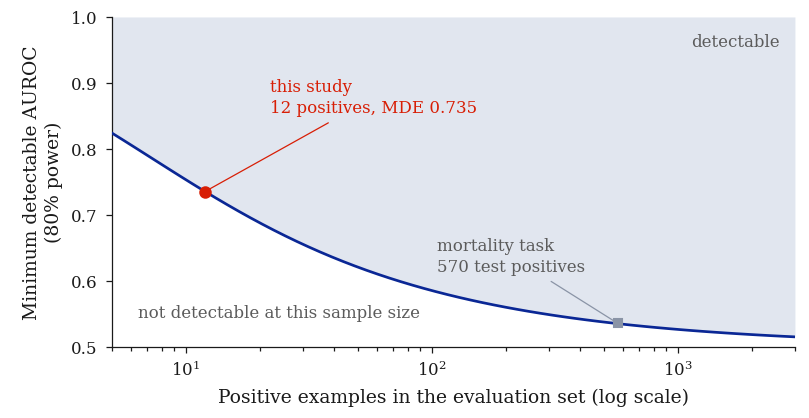

In [18]:
fig, ax = plt.subplots(figsize=(FIGW, 2.75))
canvas(fig)
fig.subplots_adjust(left=0.135, right=0.985, top=0.965, bottom=0.165)
ax.fill_between(n_pos_grid, np.clip(mde_grid, .5, 1), 1.0, color=PALE, alpha=.55, lw=0, zorder=1)
ax.plot(n_pos_grid, np.clip(mde_grid, 0.5, 1.0), color=BLUE2, lw=1.3, zorder=3)
ax.text(2600, 0.955, "detectable", fontsize=8.0, color=MUTE, ha="right")
ax.text(6.4, 0.545, "not detectable at this sample size", fontsize=8.0, color=MUTE)
# The study is the one accented mark. The comparator recedes to grey, and the
# two also differ in shape, so a greyscale print keeps them apart.
ax.plot([mort_n_pos], [mort_mde], "s", color=GREY, ms=4.2, zorder=5)
ax.annotate(f"mortality task\n{mort_n_pos} test positives", (mort_n_pos, mort_mde),
            xytext=(105, 0.615), fontsize=8.0, color=MUTE, linespacing=1.3,
            arrowprops=dict(arrowstyle="-", lw=.6, color=GREY))
ax.plot([n_pos_study], [mde_study], "o", color=SCARLET, ms=5.0, zorder=5)
ax.annotate(f"this study\n{n_pos_study} positives, MDE {mde_study:.3f}",
            (n_pos_study, mde_study), xytext=(22, 0.855),
            fontsize=8.0, color=SCARLET, linespacing=1.3,
            arrowprops=dict(arrowstyle="-", lw=.6, color=SCARLET))
ax.set_xscale("log"); ax.set_xlabel("Positive examples in the evaluation set (log scale)")
ax.set_ylabel(f"Minimum detectable AUROC\n({power_study*100:.0f}% power)", linespacing=1.3)
ax.set_ylim(0.5, 1.0); ax.set_xlim(5, 3000)
ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
lean(ax, ybounds=(0.5, 1.0))
if SHOW_INFIGURE_TITLES: ax.set_title("What each evaluation in this thesis could have seen",
             loc="left", fontsize=9.5, pad=8)

save_fig(fig, "fig-power.pdf")
plt.show()


## Figure 8: `fig-forest`

**Step 1. The data.** Read from `results/accord/stats/intervals.json`, `results/accord/decontam/corrected_gold_metrics.json`, `results/accord/control/final_report.json`, `results/task_runs.json`, `results/accord/scaling/scaling_results.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [19]:
p_intervals = os.path.join(RESULTS_ACCORD, "stats", "intervals.json")
d_intervals = json.load(open(p_intervals))
iv = d_intervals["E2_mcc_intervals"]

# The register keys are turned into readable names here. Presentation only: the
# same four systems, spelled the way the rest of the thesis spells them.
NICE = {"gpt4o_zeroshot": "GPT-4o zero-shot", "gpt4o_fewshot": "GPT-4o few-shot",
        "accord_binary_at_0.5_253core": "ACCORD at 0.5",
        "llama_baseline": "Llama 3 8B"}
# Eight estimates in three families. They were previously eight rows on one
# sorted position axis, which put a Matthews correlation, an AUROC and an
# accuracy gap in a single ranking and invited the reader to compare the length
# of one against the length of another. They do not share a unit and cannot be
# compared that way. Grouping them, naming the unit once per group and ruling a
# hairline between the groups says what the axis actually supports: within a
# family the rows are comparable, across families only the position against zero
# is.
fam_mcc = [((NICE.get(k, k) + f" ({v['n']} pairs)") if k.startswith("accord")
            else NICE.get(k, k), v["mcc"], v["ci95"][0], v["ci95"][1])
           for k, v in iv.items()]

p_decontam = os.path.join(RESULTS_ACCORD, "decontam", "corrected_gold_metrics.json")
d_decontam = json.load(open(p_decontam))
auroc_full = d_decontam["aggregate"]["ensemble_auroc"]
ci_full = d_decontam["aggregate"]["ensemble_ci95"]

# Defect-free stratum, decontaminated. This row used to carry the E3 numbers from
# stats/intervals.json (0.5078, CI [0.2217, 0.7615]), which are computed on the
# contaminated released scores, so it was not comparable with the row above it.
p_control = os.path.join(RESULTS_ACCORD, "control", "final_report.json")
d_control = json.load(open(p_control))
df34 = d_control["ensemble_mean_of_seed_scores"]["gold_defect_free_rule34"]
fam_auroc = [
    ("Decontaminated ensemble", auroc_full - 0.5, ci_full[0] - 0.5, ci_full[1] - 0.5),
    ("Defect-free stratum", df34["auroc"] - 0.5,
     df34["bootstrap"]["ci95"][0] - 0.5, df34["bootstrap"]["ci95"][1] - 0.5),
]

p_task_runs = os.path.join(RESULTS, "task_runs.json")
d_task_runs = json.load(open(p_task_runs))
pb2 = [d_task_runs[f"concat_s{s}"]["auroc"] for s in (1, 2, 3)]
ou2 = [d_task_runs[f"ours_current_s{s}"]["auroc"] for s in (0, 1, 2)]
g = statistics.mean(pb2) - statistics.mean(ou2)
se = math.sqrt(statistics.stdev(pb2) ** 2 / 3 + statistics.stdev(ou2) ** 2 / 3)

p_scaling = os.path.join(RESULTS_ACCORD, "scaling", "scaling_results.json")
d_scaling = json.load(open(p_scaling))
p100 = [x["accuracy"] for x in d_scaling if x["tag"] == "scratch_100M"]
pbert = [x["accuracy"] for x in d_scaling if x["tag"] == "pretrained_bert"]
g44 = statistics.mean(pbert) - statistics.mean(p100)
se44 = math.sqrt(statistics.stdev(pbert) ** 2 / 3 + statistics.stdev(p100) ** 2 / 3)
fam_gap = [
    ("In-hospital mortality, AUROC", g, g - 1.96 * se, g + 1.96 * se),
    ("AG News at 100M, accuracy", g44, g44 - 1.96 * se44, g44 + 1.96 * se44),
]

# Families run down the page in the order the thesis argues them; within a
# family the rows are sorted, because there the position axis does rank.
# One hue per family, not per row. On this canvas the distinction that has to
# survive is which unit a row is measured in, because that is the only thing the
# position axis does not support comparing across; the four systems in the first
# family are separated by their own row labels, as they are everywhere else in
# the set, and take the family's colour here rather than their own.
FAMILIES = [("Matthews correlation", fam_mcc, BLUE2),
            ("AUROC above chance", fam_auroc, GREEN),
            ("Pretraining gap, pretrained minus from scratch", fam_gap, ORANGE)]
for _, rs, _hue in FAMILIES:
    rs.sort(key=lambda r: r[1])

# Lay the rows out bottom up: one unit per row, the family heading half a unit
# above the family's top row, and the hairline in the band above that.
placed, seps, heads, y = [], [], [], 0.0
for fi, (fam, rs, hue) in enumerate(reversed(FAMILIES)):
    for r in rs:
        placed.append((y, r, hue)); y += 1.0
    y -= 1.0
    heads.append((y + 0.52, fam, {BLUE2: BLUE2_T, GREEN: GREEN_T,
                                  ORANGE: ORANGE_T}[hue]))
    y += 1.30
    if fi < len(FAMILIES) - 1:
        seps.append(y)
        y += 0.72
rows = [r for _, r, _h in placed]
y_top_row = placed[-1][0]
y_ceiling = y_top_row + 1.00

print("fig-forest: values plotted (three families, sorted within each)")
for lab, est, lo, hi in rows:
    crosses = lo <= 0 <= hi
    print(f"  {lab:38s} est={est:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  {'crosses zero' if crosses else 'excludes zero'}")

fig-forest: values plotted (three families, sorted within each)
  In-hospital mortality, AUROC           est=+0.0031  95% CI [-0.0111, +0.0173]  crosses zero
  AG News at 100M, accuracy              est=+0.0518  95% CI [+0.0496, +0.0540]  excludes zero
  Decontaminated ensemble                est=+0.0145  95% CI [-0.1790, +0.2034]  crosses zero
  Defect-free stratum                    est=+0.0469  95% CI [-0.2582, +0.3281]  crosses zero
  Llama 3 8B                             est=-0.0436  95% CI [-0.2337, +0.0563]  crosses zero
  ACCORD at 0.5 (253 pairs)              est=-0.0070  95% CI [-0.1626, +0.0753]  crosses zero
  GPT-4o few-shot                        est=+0.0117  95% CI [-0.1120, +0.1319]  crosses zero
  GPT-4o zero-shot                       est=+0.1089  95% CI [-0.0319, +0.2484]  crosses zero


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-forest.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-forest.pdf


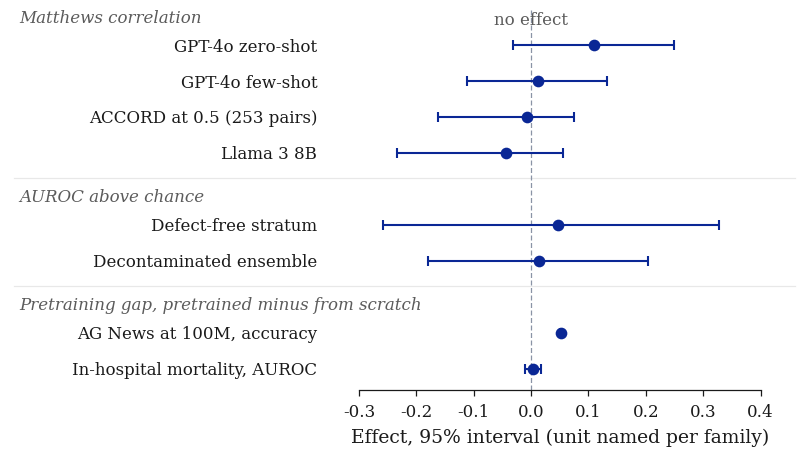

In [20]:
fig, ax = plt.subplots(figsize=(FIGW, 3.00))
canvas(fig)
fig.subplots_adjust(left=0.400, right=0.985, top=0.985, bottom=0.140)
# Colour by family, never by whether an interval contains zero. That fact is
# already drawn, by whether the interval crosses the line; saying it again in a
# second colour states one fact twice and needs a key to decode. Nothing here
# takes the accent either: this figure's claim is that the whole column sits on
# the line, which no single mark carries.
for yy, (lab, e, lo, hi), hue in placed:
    ax.errorbar([e], [yy], xerr=[[e-lo], [hi-e]], fmt="o", color=hue, **ERRBAR, **DOT)
ax.axvline(0, **CHANCE_STYLE)
gt = ax.get_yaxis_transform()
for ys in seps:
    ax.plot([-0.66, 1.0], [ys, ys], transform=gt, color=GRID, lw=0.6,
            clip_on=False, zorder=0)
# The family heading is this figure's direct label for the family, so it is set
# in the family's own colour rather than in the annotation grey. It is also the
# redundancy: in a greyscale print the heading, the hairline and the position
# separate the three families, and the hue is only the fast read.
for yh, fam, fam_t in heads:
    ax.text(-0.65, yh, fam, transform=gt, ha="left", va="bottom", fontsize=8.0,
            color=fam_t, style="italic", clip_on=False)
ax.set_yticks([yy for yy, _, _h in placed])
ax.set_yticklabels([r[0] for r in rows], fontsize=8.0, linespacing=1.25)
ax.set_xlabel("Effect, 95% interval (unit named per family)")
ax.set_xlim(-0.36, 0.46)
ax.set_xticks([-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3, 0.4])
ax.set_ylim(-0.60, y_ceiling)
n_cross = sum(1 for r in rows if r[2] <= 0 <= r[3])
if SHOW_INFIGURE_TITLES: ax.set_title(f"{n_cross} of {len(rows)} headline estimates cross zero",
             loc="left", fontsize=9.5, pad=8)
ax.text(0, y_top_row + 0.46, "no effect", fontsize=8.0, color=MUTE, ha="center",
        va="bottom")
# The measured axis keeps its spine, extended past the widest cap so no interval
# runs off the end of the scale it is read on. The categorical axis has none: a
# rule beside eight row labels reads as a bracket over all eight.
lean(ax, xbounds=(-0.3, 0.4))
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)

save_fig(fig, "fig-forest.pdf")
plt.show()


## Figure 9: `fig-survey-audit`

**Step 1. The data.** Read from `results/accord/survey/coding_summary.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [21]:
p_coding = os.path.join(RESULTS_ACCORD, "survey", "coding_summary.json")
coding = json.load(open(p_coding))

n_total = coding["n_included_papers"]
dist = coding["distributions"]
n_strict = dist["audits_selection_strict"]["yes"]
n_literal = dist["audits_selection_literal"]["yes"]
n_neither = dist["audits_selection_literal"]["no"]
# The middle segment is the population the two readings disagree about. It is
# not stored on its own line and is not invented: it is the permissive count
# less the strict count, both read above, and the three segments are checked
# against the denominator before anything is drawn.
n_permissive_only = n_literal - n_strict
assert n_strict + n_permissive_only + n_neither == n_total

print("fig-survey-audit: values plotted")
print(f"  coded papers                    {n_total:>4d}")
print(f"  strict reading                  {n_strict:>4d}  "
      f"{n_strict / n_total * 100:5.1f}%")
print(f"  permissive reading only         {n_permissive_only:>4d}  "
      f"{n_permissive_only / n_total * 100:5.1f}%")
print(f"  neither reading                 {n_neither:>4d}  "
      f"{n_neither / n_total * 100:5.1f}%")


fig-survey-audit: values plotted
  coded papers                      75
  strict reading                     4    5.3%
  permissive reading only           10   13.3%
  neither reading                   61   81.3%


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-survey-audit.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-survey-audit.pdf


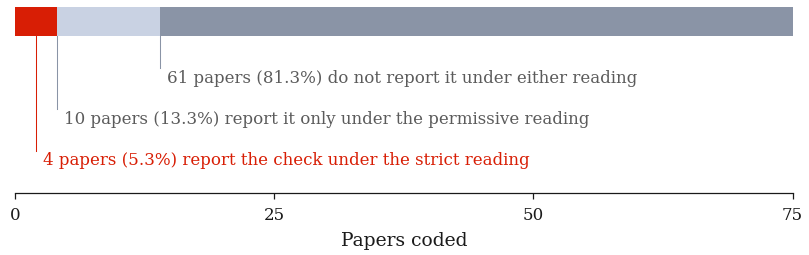

In [22]:
fig, ax = plt.subplots(figsize=(FIGW, 1.66))
canvas(fig)
# The right margin holds the last tick label, not the bar: ticked to the
# denominator, the "75" is centred on the axis end, so half of it sits outside
# the axes and the canvas has to be wide enough to contain it.
fig.subplots_adjust(left=0.015, right=0.982, top=0.985, bottom=0.235)

# Counts, not percentages, on the axis: the denominator is 75 and the top tick
# is 75, so the whole is on the canvas and every segment is read against it
# directly.
ax.set_xlim(0, n_total)
ax.set_ylim(0, 1)

y_bar_lo, y_bar_hi = 0.845, 1.0
segments = [
    (n_strict, SCARLET, SCARLET,
     f"{n_strict} papers ({n_strict / n_total * 100:.1f}%) report the check "
     "under the strict reading"),
    # The middle segment is a real, named population, not a leftover: the
    # papers the two readings disagree about. It used to be drawn in the pale
    # band tone, which is the tone this set uses for structure, so the one
    # thing on the canvas that is a finding looked like backing. It now carries
    # a series hue, light enough to stay behind the claim segment and dark
    # enough to be a segment rather than a shadow.
    (n_permissive_only, SKY, MUTE,
     f"{n_permissive_only} papers ({n_permissive_only / n_total * 100:.1f}%) "
     "report it only under the permissive reading"),
    (n_neither, GREY, MUTE,
     f"{n_neither} papers ({n_neither / n_total * 100:.1f}%) do not report "
     "it under either reading"),
]

left = 0.0
placed = []
for n, fill, text_colour, label in segments:
    ax.add_patch(mpatches.Rectangle((left, y_bar_lo), n, y_bar_hi - y_bar_lo,
                                    facecolor=fill, edgecolor="none", zorder=2))
    placed.append((left, n, fill, text_colour, label))
    left += n

# A staircase of direct labels: each one begins under the left edge of its own
# segment and is tied to it by a leader dropped from that edge, so no key is
# needed to say which label belongs to which colour. The four-paper segment is a
# quarter of an inch on the page and will not hold a label inside it, and
# neither pale nor grey may carry text, so all three labels sit below the bar.
#
# The rows run widest segment first, which is what keeps the leaders off the
# type: a leader dropped from a segment further left passes only rows whose text
# starts further right, so it never strikes through a label. In the other order,
# every leader crossed the two labels above it.
y_rows = [0.615, 0.395, 0.175]
for (left, n, fill, text_colour, label), y_row in zip(
        sorted(placed, key=lambda p: -p[0]), y_rows):
    leader = SCARLET if fill is SCARLET else GREY
    # Leaders anchor at the segment's left edge, with one stated exception:
    # a segment starting at x = 0 anchors at its midpoint, because a
    # full-height hairline directly above the 0 tick, on an axes whose left
    # spine is deliberately absent, reads as a spine in claim colour.
    anchor = left + n / 2 if left == 0 else left
    ax.plot([anchor, anchor], [y_row + 0.055, y_bar_lo], color=leader,
            lw=0.5, zorder=1)
    ax.text(anchor + 0.7, y_row, label, ha="left", va="center",
            fontsize=8.0, color=text_colour)

ax.set_xlabel("Papers coded")
ax.set_xticks([0, 25, 50, n_total])
ax.set_yticks([])
# The count axis measures something and keeps its spine; the bar has one row and
# no categorical axis, so nothing runs up the left edge.
lean(ax, xbounds=(0, n_total))
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)

save_fig(fig, "fig-survey-audit.pdf")
plt.show()


## Figure 10: `fig-disc-strata`

**Step 1. The data.** Read from `results/accord/decontam/corrected_gold_metrics.json`, `results/accord/control/final_report.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [23]:
p_decontam = os.path.join(RESULTS_ACCORD, "decontam", "corrected_gold_metrics.json")
d_decontam = json.load(open(p_decontam))

# Both rows now come from the decontaminated run. The defect-free stratum used to
# be read from stats/intervals.json E3, which is computed on the contaminated
# released scores, so the two rows were not comparable. Its stratified CI and its
# dropped-resample count belong to that superseded bootstrap and are no longer
# drawn; there is no decontaminated Mann-Whitney p for this stratum on disk, so
# that row carries none.
p_control = os.path.join(RESULTS_ACCORD, "control", "final_report.json")
d_control = json.load(open(p_control))
e3 = d_control["ensemble_mean_of_seed_scores"]["gold_defect_free_rule34"]

agg = d_decontam["aggregate"]
# Sample sizes, positives and the Mann-Whitney p live in the row label, out of
# the plot area, so the data region holds nothing but the two estimates and
# their intervals. The estimate itself is read off the axis.
rows = [
    ("All non-ambiguous pairs\n(decontaminated 3-seed ensemble)\n"
     f"n={d_decontam['n']}, {d_decontam['n_positives']} positives, "
     f"MWU p={agg['ensemble_mannwhitney_p']:.3f}",
     agg["ensemble_auroc"], agg["ensemble_ci95"]),
    ("Rules 3 and 4 only\n(exemplar-defect-free stratum)\n"
     f"n={e3['n']}, {e3['pos']} positives",
     e3["auroc"], e3["bootstrap"]["ci95"]),
]

print("fig-disc-strata: values plotted")
for label, auroc, ci in rows:
    print(f"  {label.replace(chr(10), ' '):85s} AUROC={auroc:.4f}  CI=[{ci[0]:.3f},{ci[1]:.3f}]")
print(f"  bootstrap: {d_control['bootstrap_n_resamples']} resamples, "
      f"{e3['bootstrap']['n_boot_valid']} valid on the defect-free stratum")
print("  first row is labelled 'non-ambiguous', not 'annotated': the annotated set is 299,")
print("  and the 46 ambiguous pairs are excluded from the 253 plotted.")

fig-disc-strata: values plotted
  All non-ambiguous pairs (decontaminated 3-seed ensemble) n=253, 12 positives, MWU p=0.867 AUROC=0.5145  CI=[0.321,0.703]
  Rules 3 and 4 only (exemplar-defect-free stratum) n=134, 6 positives                  AUROC=0.5469  CI=[0.242,0.828]
  bootstrap: 10000 resamples, 10000 valid on the defect-free stratum
  first row is labelled 'non-ambiguous', not 'annotated': the annotated set is 299,
  and the 46 ambiguous pairs are excluded from the 253 plotted.


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-disc-strata.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-disc-strata.pdf


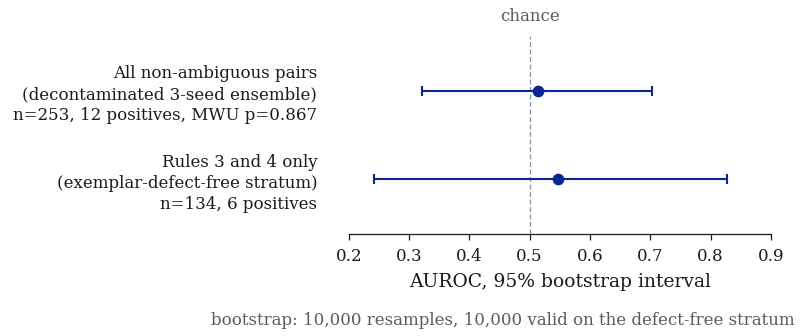

In [24]:
fig, ax = plt.subplots(figsize=(FIGW, 2.20))
canvas(fig)
fig.subplots_adjust(left=0.400, right=0.985, top=0.900, bottom=0.300)
ys = np.arange(len(rows))[::-1]
ax.axvline(0.5, **CHANCE_STYLE)
# Two rows, two hues, because they are two different populations scored by two
# different models and the caption has to say so in words when they share one
# colour. The defect-free stratum takes the truth hue: it is the subset whose
# evidence is correct by construction, which is the closest this evaluation
# gets to clean ground.
row_hues = [BLUE2, GREEN]
for y, (label, auroc, ci), hue in zip(ys, rows, row_hues):
    ax.errorbar([auroc], [y], xerr=[[auroc - ci[0]], [ci[1] - auroc]], fmt="o",
                color=hue, zorder=3, **ERRBAR, **DOT)
ax.set_yticks(ys)
ax.set_yticklabels([r[0] for r in rows], fontsize=8.0, linespacing=1.3)
ax.set_xlim(0.16, 0.94)
ax.set_ylim(-0.62, 1.62)
ax.set_xticks([0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
ax.set_xlabel("AUROC, 95% bootstrap interval")
ax.text(0.5, 1.74, "chance", fontsize=8.0, color=MUTE, ha="center", va="bottom")
# The spine now runs past the stratum's upper bound at 0.828, which it used to
# stop short of, so neither interval ends beyond the scale. The categorical axis
# has no spine: the vertical rule that used to join these two rows read as a
# bracket, and a bracket asserts that the lower row is a subset of the upper
# one. It is not. The caption says in as many words that the second row is a
# different model on a different stratum, and the figure was contradicting its
# own caption.
lean(ax, xbounds=(0.2, 0.9))
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
# Note sits below the axes, clear of both intervals.
fig.text(0.985, 0.025,
         f"bootstrap: {d_control['bootstrap_n_resamples']:,} resamples, "
         f"{e3['bootstrap']['n_boot_valid']:,} valid on the defect-free stratum",
         ha="right", fontsize=8.0, color=MUTE)
if SHOW_INFIGURE_TITLES: fig.suptitle("On evidence correct by construction, ranking is at chance,\nnot merely attenuated toward it",
             fontsize=8.3, y=0.99)
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.03,
         "No ROC curve is drawn: per-pair prediction scores are not committed to this repository (MIMIC-III DUA\n"
         "restricts released files to aggregates). Panels show the committed point estimate and its bootstrap CI instead.",
         ha="center", fontsize=8.0, color=MUTE)

save_fig(fig, "fig-disc-strata.pdf")
plt.show()


## Figure 11: `fig-scaling`

**Step 1. The data.** Read from `results/accord/scaling/scaling_results.json`, `results/task_runs.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [25]:
p_scaling = os.path.join(RESULTS_ACCORD, "scaling", "scaling_results.json")
d_scaling = json.load(open(p_scaling))
by, params_by_tag = {}, {}
for x in d_scaling:
    by.setdefault(x["tag"], []).append(x["accuracy"])
    params_by_tag[x["tag"]] = x["non_emb_params"]
tags = ["scratch_10M", "scratch_30M", "scratch_100M"]
xs = [params_by_tag[t] for t in tags]
mu = [statistics.mean(by[t]) for t in tags]
sd = [statistics.stdev(by[t]) for t in tags]
pm, ps, pp = statistics.mean(by["pretrained_bert"]), statistics.stdev(by["pretrained_bert"]), params_by_tag["pretrained_bert"]

p_task_runs = os.path.join(RESULTS, "task_runs.json")
d_task_runs = json.load(open(p_task_runs))
pb = [d_task_runs[f"concat_s{s}"]["auroc"] for s in (1, 2, 3)]
ou = [d_task_runs[f"ours_current_s{s}"]["auroc"] for s in (0, 1, 2)]
pbm, pbs = statistics.mean(pb), statistics.stdev(pb)
oum, ous = statistics.mean(ou), statistics.stdev(ou)
gap = pbm - oum
clinical_params = d_task_runs["ours_current_s0"]["non_emb_params"]

print("fig-scaling: values plotted")
print(f"  AG News: pretrained_bert mean +/- std = {pm:.4f} +/- {ps:.4f}  ({pp / 1e6:.0f}M params)")
for t, x, m, s in zip(tags, xs, mu, sd):
    print(f"  AG News: {t:14s} mean +/- std = {m:.4f} +/- {s:.4f}  ({x / 1e6:.1f}M params)  gap to pretrained = {pm - m:+.4f}")
print(f"  clinical task: PubMedBERT (concat_s1..3) AUROC mean +/- std = {pbm:.4f} +/- {pbs:.4f}")
print(f"  clinical task: from-scratch (ours_current_s0..2) AUROC mean +/- std = {oum:.4f} +/- {ous:.4f}  ({clinical_params / 1e6:.1f}M params)")
print(f"  clinical task gap: {gap:+.4f}")

fig-scaling: values plotted
  AG News: pretrained_bert mean +/- std = 0.9396 +/- 0.0010  (86M params)
  AG News: scratch_10M    mean +/- std = 0.8790 +/- 0.0040  (10.6M params)  gap to pretrained = +0.0606
  AG News: scratch_30M    mean +/- std = 0.8833 +/- 0.0009  (31.9M params)  gap to pretrained = +0.0563
  AG News: scratch_100M   mean +/- std = 0.8878 +/- 0.0016  (99.2M params)  gap to pretrained = +0.0518
  clinical task: PubMedBERT (concat_s1..3) AUROC mean +/- std = 0.7693 +/- 0.0102
  clinical task: from-scratch (ours_current_s0..2) AUROC mean +/- std = 0.7662 +/- 0.0073  (10.6M params)
  clinical task gap: +0.0031


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-scaling.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-scaling.pdf


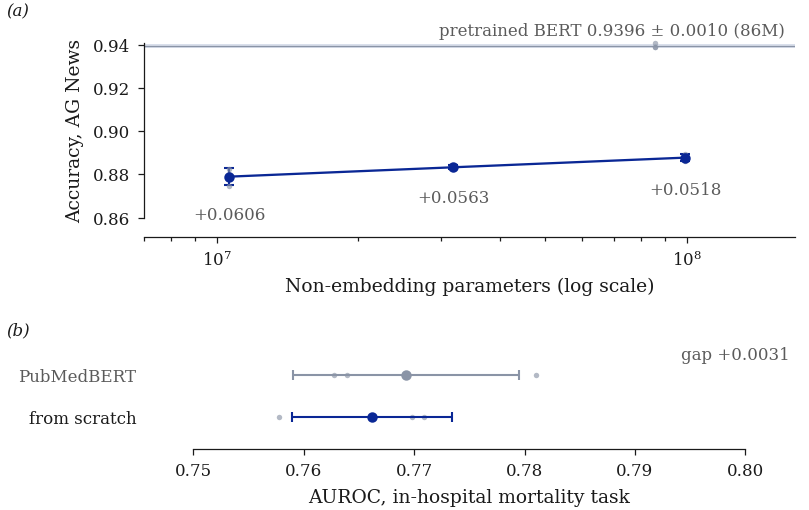

In [26]:
# Two panels, not a panel with a floating inset. The clinical comparison is a
# second experiment on a second task with a second metric; an inset says
# "detail of the panel behind me", which this is not, and it borrowed the host
# panel's frame so it had no way to name its own unit. As a panel it has its
# own frame, its own axis label naming the metric and the task, and its own
# letter.
fig, (ax, axb) = plt.subplots(2, 1, figsize=(FIGW, 3.34),
                              gridspec_kw={"height_ratios": [2.00, 1.0]})
canvas(fig)
fig.subplots_adjust(left=0.175, right=0.985, top=0.965, bottom=0.115, hspace=0.66)
# Two arms, two hues. The pretrained arm is the reference this figure measures
# against, but it is a measured arm with three seeds and a spread of its own,
# not a chance line, so it is no longer drawn in the grey this set reserves for
# structure: it takes the hue every other reference-standard arm in the set
# takes, and its band, its line and its label are all that one hue, because an
# interval belongs to the mark it came from.
ax.axhspan(pm-ps, pm+ps, color=GREEN, alpha=0.22, linewidth=0, zorder=1)
ax.axhline(pm, color=GREEN, lw=0.8, zorder=2)
ax.text(1.62e8, pm+0.0030, f"pretrained BERT {pm:.4f} ± {ps:.4f} ({pp/1e6:.0f}M)",
        fontsize=8.0, color=GREEN_T, va="bottom", ha="right")
# Every seed that went into each mean is drawn behind it, on both panels, in
# the same small grey dot: the caps here are the seed standard deviation of
# three committed runs, not an analytic bound, so the runs themselves are on
# the canvas. The seeds share the mean's x (they are the same model size), so
# the interval is drawn first and the seeds over it: drawn under the interval
# they were hidden by its own rule and the panel read as caps with no seeds.
# The mean is drawn last and still sits in front, so where the three seeds
# agree to within the width of a marker they are simply the mark itself.
ax.errorbar(xs, mu, yerr=sd, fmt="none", ecolor=BLUE2, zorder=3, **ERRBAR)
for x, t in zip(xs + [pp], tags + ["pretrained_bert"]):
    ax.plot([x] * len(by[t]), by[t], "o", color=GREY, ms=2.6, markeredgewidth=0,
            alpha=0.65, zorder=4)
ax.plot(xs, mu, "-o", color=BLUE2, ms=4.0, lw=1.1, zorder=5)
# The gap labels sit below their points; the x limits are set wide enough that the
# leftmost one is not cut off by the axis, as it was before.
for x, m, s, t in zip(xs, mu, sd, tags):
    ax.annotate(f"{pm-m:+.4f}", (x, m - s), textcoords="offset points", xytext=(0, -10),
                ha="center", va="top", fontsize=8.0, color=MUTE)
ax.set_xscale("log"); ax.set_xlabel("Non-embedding parameters (log scale)")
ax.set_ylabel("Accuracy, AG News"); ax.set_ylim(0.851, 0.950)
# The top tick has to reach past the pretrained reference. Ticked to 0.93 the
# scale stopped below the band this panel is measured against, so the reference
# line and its own seeds sat above the last value the axis named. Even steps,
# so the ticks still read as one scale rather than a regular ladder with one
# odd rung added at the top to reach the reference.
ax.set_yticks([0.86, 0.88, 0.90, 0.92, 0.94])
ax.set_xlim(7.0e6, 1.7e8)
lean(ax, ybounds=(0.86, 0.941))
if SHOW_INFIGURE_TITLES: ax.set_title("Pretraining is worth five points here, and more parameters do not close it",
             loc="left", fontsize=9.5, pad=8)

# (b) The clinical arms. Same grammar and the same two hues as panel (a): the
# from-scratch arm blue, the pretrained arm the reference hue, each mean with
# its three seeds drawn behind it in grey. The two panels are two tasks, so
# holding the arm colours across them is the only thing on the canvas saying
# that the same comparison is being made twice. No accent: the claim here is
# the size of the gap, which is a relation between two marks rather than either
# of them.
for i, (vals, mean, sdv, colour) in enumerate(
        ((ou, oum, ous, BLUE2), (pb, pbm, pbs, GREEN))):
    axb.plot(vals, [i] * len(vals), "o", color=GREY, ms=2.6, markeredgewidth=0,
             alpha=0.65, zorder=2)
    axb.errorbar([mean], [i], xerr=[sdv], fmt="o", color=colour, ms=4.0,
                 ecolor=colour, zorder=3, **ERRBAR)
axb.set_yticks([0, 1])
axb.set_yticklabels(["from scratch", "PubMedBERT"], fontsize=8.0)
# Each row label is the direct label for its own arm, so it is set in that
# arm's colour at the value type needs. That label is also what separates the
# two arms in a greyscale print.
for lab, c in zip(axb.get_yticklabels(), (BLUE2_T, GREEN_T)):
    lab.set_color(c)
# Bounds and ticks reach past the outermost seed (0.7578) and the widest
# cap, so nothing in the panel sits off the end of its own scale.
axb.set_ylim(-0.75, 1.75); axb.set_xlim(0.7455, 0.8045)
axb.set_xticks([0.75, 0.76, 0.77, 0.78, 0.79, 0.80])
axb.set_xlabel("AUROC, in-hospital mortality task")
axb.text(0.8040, 1.66, f"gap {gap:+.4f}", fontsize=8.0, color=MUTE,
         ha="right", va="top")
axb.tick_params(labelsize=8)
lean(axb, xbounds=(0.75, 0.80))
axb.spines["left"].set_visible(False)
axb.tick_params(axis="y", length=0)

for a_, tag in ((ax, "(a)"), (axb, "(b)")):
    p = a_.get_position()
    fig.text(0.004, p.y1 + 0.008, tag, ha="left", va="bottom",
             fontsize=8.0, style="italic", color=INK)

save_fig(fig, "fig-scaling.pdf")
plt.show()


## Figure 12: `fig-threshold-surface`

**Step 1. The data.** Read from `results/accord/selection/threshold_robustness_results.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [27]:
p_thresh = os.path.join(RESULTS_ACCORD, "selection", "threshold_robustness_results.json")
d_thresh = json.load(open(p_thresh))
df = pd.DataFrame(d_thresh["cells"])
piv = df.pivot_table(index="achieved_rate", columns="beta", values="demographic_parity_gap", aggfunc="mean")
mde = df.pivot_table(index="achieved_rate", columns="beta", values="mde_demographic_parity_gap", aggfunc="mean")
R, B, Z, M = piv.index.values, piv.columns.values, piv.values, mde.values
e9_rate = d_thresh["original_e9_population_pred_pos_rate"]

# Named setting, not read from this file: the audit's own demographic-parity tolerance.
TOLERANCE = 0.05

print("fig-threshold-surface: values plotted")
print(f"  grid: {Z.shape[0]} operating points x {Z.shape[1]} selection strengths = {Z.size} cells")
print(f"  demographic-parity gap range: [{np.nanmin(Z):.4f}, {np.nanmax(Z):.4f}]")
print(f"  minimum-detectable-gap range: [{np.nanmin(M):.4f}, {np.nanmax(M):.4f}]")
n_under = int((M > TOLERANCE).sum())
print(f"  cells underpowered at TOLERANCE={TOLERANCE}: {n_under} of {M.size}")
print(f"  original E9 operating point (predicted-positive rate): {e9_rate:.4f}")

# Viridis: perceptually uniform, monotone in lightness end to end, and safe
# under every common dichromacy, which is why it is the standard for a field
# like this one. It replaces a five-stop ramp in a single blue. The ramp was
# defensible and it was also the reason a surface of 270 measured cells read as
# one wash: a single hue can only spend lightness, so the interesting middle of
# this field, between about 0.04 and 0.12, occupied one narrow band of pale
# blue. Viridis spends hue as well, so the same middle is a visible traverse
# from blue through teal to green, and the greyscale reading survives because
# viridis is still monotone in lightness: dark is low, light is high, in print
# and on paper both.
cmap = plt.get_cmap("viridis")

fig-threshold-surface: values plotted
  grid: 18 operating points x 15 selection strengths = 270 cells
  demographic-parity gap range: [0.0021, 0.2001]
  minimum-detectable-gap range: [0.0305, 0.0600]
  cells underpowered at TOLERANCE=0.05: 195 of 270
  original E9 operating point (predicted-positive rate): 0.1994


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-threshold-surface.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-threshold-surface.pdf


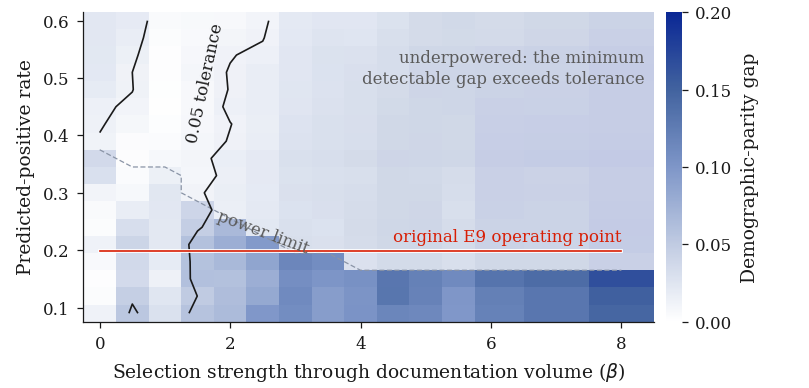

In [28]:
fig, ax = plt.subplots(figsize=(FIGW, 2.55))
canvas(fig)
fig.subplots_adjust(left=0.100, right=0.855, top=0.975, bottom=0.165)
im = ax.pcolormesh(B, R, Z, cmap=cmap, shading="nearest", vmin=0, vmax=0.20)

# veil the underpowered region instead of hatching it
# Wash the underpowered region. At the old strength the veil left a cell whose
# gap the sweep cannot measure looking very much like a cell whose gap it can,
# so a figure whose entire point is that most of this surface has no power was
# drawing announced noise at nearly the strength of signal. At this strength the
# two regions are different surfaces at a glance, and the values underneath are
# still legible against the colour bar for anyone reading them.
veil = np.where(M > TOLERANCE, 0.76, 0.0)
ax.pcolormesh(B, R, veil, cmap=LinearSegmentedColormap.from_list("v", ["#ffffff00", "#ffffff"]),
              shading="nearest", vmin=0, vmax=1, zorder=2)
# The power boundary runs with washed-out paper on one side of it and full
# colour on the other, so a single flat tone is legible on one side only. It is
# cased in white, the same treatment the operating line and the bar intervals
# in this set already carry, and so is its label.
ax.contour(B, R, (M > TOLERANCE).astype(float), levels=[0.5],
           colors="white", linewidths=1.6, linestyles=[(0, (4, 2))], zorder=3)
ax.contour(B, R, (M > TOLERANCE).astype(float), levels=[0.5],
           colors=GREY, linewidths=0.6, linestyles=[(0, (4, 2))], zorder=3.1)
# The boundary is labelled at the boundary, riding it at its own angle, in the
# text tone that belongs to a grey reference line. The block of text in the
# region says what the region means; this says what the line is.
ax.text(2.46, 0.218, "power limit", fontsize=8.0, color=MUTE,
        ha="center", va="bottom", rotation=-20.4, rotation_mode="anchor",
        zorder=7, path_effects=[pe.withStroke(linewidth=2.0, foreground="white")])
ax.text(8.35, 0.55, "underpowered: the minimum\ndetectable gap exceeds tolerance",
        ha="right", va="top", fontsize=8.0, color=MUTE, linespacing=1.3, zorder=7)

# Every fragment of the tolerance contour is drawn whole, including the short
# one near the bottom left. The label is placed beside the longest fragment
# rather than inline in it, because an inline label is cut out of the line it
# names, and on a surface this broken a gap in a contour is indistinguishable
# from a fragment somebody removed.
#
# The tolerance contour crosses the field at a quarter of the colour bar, which
# on this colormap is a dark blue, so the near-black line it used to be drawn
# in disappeared into it. It keeps its colour and gains a white casing, which
# is what the rest of this set does whenever a line has to cross both a fill
# and the paper. Its label sits in the washed region and needs none.
ax.contour(B, R, Z, levels=[TOLERANCE], colors="white", linewidths=2.0, zorder=3.9)
cs = ax.contour(B, R, Z, levels=[TOLERANCE], colors=INK, linewidths=0.8, zorder=4)
ax.text(1.55, 0.385, f"{TOLERANCE} tolerance", fontsize=8.0, color=INK,
        ha="left", va="bottom", rotation=78.0, rotation_mode="anchor", zorder=7)

# The operating point this study shipped: the one accented element on the canvas.
# The casing is wider and the line heavier than they were: at the old hairline
# weight the scarlet was legible but it was no longer the first thing on the
# canvas against a field now carrying four hues of its own, which is the whole
# job of the accent. It is still the only red mark here, and now also the
# heaviest line.
ax.plot(B, [e9_rate]*len(B), color="w", lw=2.6, zorder=5)
ax.plot(B, [e9_rate]*len(B), color=SCARLET, lw=1.2, zorder=6)
# Label parked at the right-hand end of the line it names. Anchored at the left
# of the panel it lay across the 0.05 contour.
ax.text(B[-1], e9_rate + 0.008, "original E9 operating point", ha="right", va="bottom",
        fontsize=8.0, color=SCARLET, zorder=7)

ax.set_xlabel(r"Selection strength through documentation volume ($\beta$)")
ax.set_ylabel("Predicted-positive rate")
ax.set_xticks([0, 2, 4, 6, 8])
ax.set_yticks([0.1, 0.2, 0.3, 0.4, 0.5, 0.6])
if SHOW_INFIGURE_TITLES: ax.set_title("The audit never becomes cleanly blind; it becomes unmeasurable",
             loc="left", fontsize=9.5, pad=16)

cb = fig.colorbar(im, ax=ax, pad=0.020, fraction=0.040)
cb.set_label("Demographic-parity gap", fontsize=9.0)
cb.set_ticks([0, 0.05, 0.10, 0.15, 0.20])
cb.ax.tick_params(labelsize=8, width=0.6, length=3)
cb.outline.set_visible(False)

save_fig(fig, "fig-threshold-surface.pdf")
plt.show()


## Figure 13: `fig-disc-actionability`

**Step 1. The data.** This figure is a schematic: it reads no result file, and the cell below says so rather than implying a source it does not have.

In [29]:
print("fig-disc-actionability: no result file is read by this cell.")
print("This figure is a schematic of a MIMIC-III field-availability fact (accord/CORRECTIONS.md, C6):")
print("  nursing notes carry CHARTTIME (a timestamp); discharge summaries carry only CHARTDATE (a date).")
print("No numeric estimate is plotted, so there is no CI to attach and nothing to source from a JSON file.")

# Widened from 10.5 to 11.6 units so the longest event label no longer runs off
# the right-hand edge, and every leader now starts outside the shaded band
# instead of crossing it. The trigger point carries one marker, not an X drawn
# on top of a dot.

fig-disc-actionability: no result file is read by this cell.
This figure is a schematic of a MIMIC-III field-availability fact (accord/CORRECTIONS.md, C6):
  nursing notes carry CHARTTIME (a timestamp); discharge summaries carry only CHARTDATE (a date).
No numeric estimate is plotted, so there is no CI to attach and nothing to source from a JSON file.


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-disc-actionability.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-disc-actionability.pdf


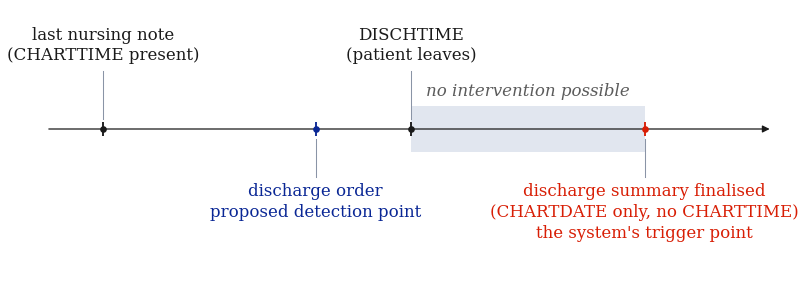

In [30]:
# One clean timeline. Events are tick-marked on a single axis, their labels
# alternate above and below on thin leaders, and the two moments the
# argument turns on carry the only accents: the point a detector could have
# fired, and the point this one actually does. Drawn on the same point grid
# as the other two schematics, one data unit to one typographic point.
W, H = FIGW, 1.84
fig, ax = plt.subplots(figsize=(W, H))
canvas(fig)
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
ax.set_xlim(0, W * 72)
ax.set_ylim(0, H * 72)
ax.axis("off")

line_y = 72.0
band_lo, band_hi = line_y - 11.0, line_y + 11.0
# (x, label, above?, accent colour or None)
events = [
    (48.0, "last nursing note\n(CHARTTIME present)", True, None),
    (150.0, "discharge order\nproposed detection point", False, BLUE),
    (196.0, "DISCHTIME\n(patient leaves)", True, None),
    (308.0, "discharge summary finalised\n(CHARTDATE only, no CHARTTIME)\n"
            "the system's trigger point", False, SCARLET),
]

# The span in which nothing can be done: a light band, labelled directly
# above itself, sitting behind the axis rather than on top of it.
ax.add_patch(mpatches.Rectangle((196.0, band_lo), 308.0 - 196.0, band_hi - band_lo,
                                facecolor=PALE, edgecolor="none", alpha=0.55,
                                zorder=0))
ax.text((196.0 + 308.0) / 2, band_hi + 3, "no intervention possible",
        ha="center", va="bottom", fontsize=8.0, style="italic", color=MUTE)

ax.annotate("", xy=(368.0, line_y), xytext=(22.0, line_y),
            arrowprops=dict(arrowstyle="-|>", color=INK, lw=0.6,
                            mutation_scale=7, shrinkA=0, shrinkB=0))
for x, label, above, accent in events:
    colour = accent or INK
    ax.plot([x, x], [line_y - 3.5, line_y + 3.5], color=colour, lw=0.9,
            solid_capstyle="butt", zorder=4)
    ax.plot([x], [line_y], "o", color=colour, markersize=3.2,
            markeredgewidth=0, zorder=5)
    if above:
        ax.plot([x, x], [line_y + 5, 100.0], color=GREY, lw=0.5, zorder=2)
        ax.text(x, 103.0, label, ha="center", va="bottom", fontsize=8.0,
                color=colour, linespacing=1.3)
    else:
        ax.plot([x, x], [line_y - 5, 49.0], color=GREY, lw=0.5, zorder=2)
        ax.text(x, 46.0, label, ha="center", va="top", fontsize=8.0,
                color=colour, linespacing=1.3)

if SHOW_INFIGURE_TITLES: ax.text(W * 36, H * 72 - 4, "The trigger fires after the patient has left",
             ha="center", va="top", fontsize=9.0)
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.02,
         "Schematic of MIMIC-III field timing (CORRECTIONS.md C6: CHARTTIME is null for every\n"
         "discharge summary). No numeric estimate is shown; not sourced from a results JSON.",
         ha="center", fontsize=8.0, color=MUTE)

save_fig(fig, "fig-disc-actionability.pdf")
plt.show()


## Figure 14: `fig-met-exchange`

**Step 1. The data.** Read from `results/accord/diag/step3_baselines.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [31]:
p_baselines = os.path.join(RESULTS_ACCORD, "diag", "step3_baselines.json")
d_baselines = json.load(open(p_baselines))
systems = {
    "ACCORD": d_baselines["accord_binary_at_0.5_253core"],
    "GPT-4o zero-shot": d_baselines["gpt4o_zeroshot"],
    "GPT-4o few-shot": d_baselines["gpt4o_fewshot"],
    "Llama 3 8B": d_baselines["llama_baseline"],
}
ref = systems["ACCORD"]
TP0, TN0, FP0, FN0 = ref["tp"], ref["tn"], ref["fp"], ref["fn"]
P = TP0 + FN0
N = TN0 + FP0

def mcc_from_counts(tp, tn, fp, fn):
    num = tp * tn - fp * fn
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return 0.0 if den == 0 else num / den

mcc0 = mcc_from_counts(TP0, TN0, FP0, FN0)

print("fig-met-exchange: values plotted")
print(f"  reference system (ACCORD): TP={TP0}, TN={TN0}, FP={FP0}, FN={FN0}  (P={P}, N={N}, n={P + N})")
print(f"  reference MCC: {mcc0:.4f}")
for name, s in systems.items():
    delta = TP0 - s["tp"]
    dtn = s["tn"] - TN0
    print(f"  {name:18s}: TP={s['tp']:3d} TN={s['tn']:3d} FP={s['fp']:3d} FN={s['fn']:3d}  delta_TP={delta:+d}  delta_TN={dtn:+d}")

fig-met-exchange: values plotted
  reference system (ACCORD): TP=11, TN=18, FP=223, FN=1  (P=12, N=241, n=253)
  reference MCC: -0.0070
  ACCORD            : TP= 11 TN= 18 FP=223 FN=  1  delta_TP=+0  delta_TN=+0
  GPT-4o zero-shot  : TP=  6 TN=176 FP= 65 FN=  6  delta_TP=+5  delta_TN=+158
  GPT-4o few-shot   : TP=  7 TN=107 FP=134 FN=  5  delta_TP=+4  delta_TN=+89
  Llama 3 8B        : TP= 11 TN= 10 FP=231 FN=  1  delta_TP=+0  delta_TN=-8


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-met-exchange.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-met-exchange.pdf


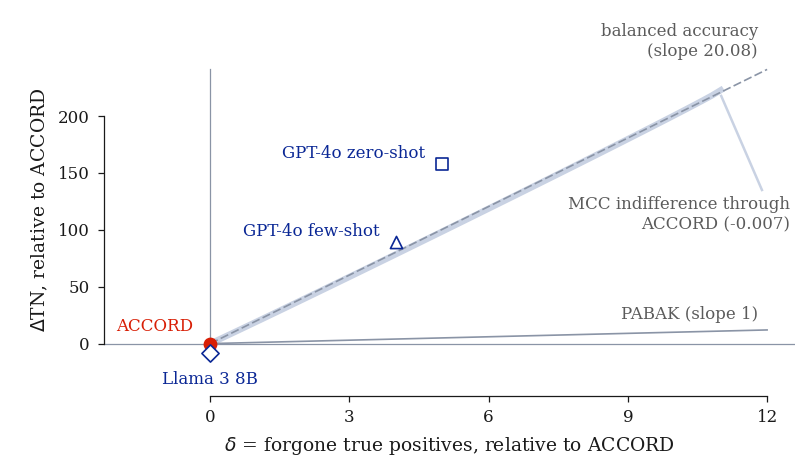

In [32]:
fig, ax = plt.subplots(figsize=(FIGW, 3.10))
canvas(fig)
fig.subplots_adjust(left=0.125, right=0.985, top=0.955, bottom=0.155)
# The three indifference lines are not measurements. They are what each
# statistic would accept, computed from the class counts, and they are the grid
# this figure reads the four systems against. So they are drawn in the reference
# grammar the rest of the set uses for a null or a chance line: grey hairlines,
# labelled at the line in the secondary text tone. Blue is returned to the thing
# that was actually measured, which is the systems.
d = np.linspace(0, P, 200)
ax.plot(d, d, color=GREY, linewidth=0.8, zorder=3)
slope_ba = N / P
ax.plot(d, d * slope_ba, color=GREY, linewidth=0.8, linestyle=(0, (5, 2)), zorder=3)

# MCC indifference curve through ACCORD's own operating point, traced
# numerically: for each delta (forgone TPs), solve for the TN that holds
# MCC constant at mcc0.
# Sweep to TP0, not to P. A system cannot forgo more true positives than it
# found, and ACCORD found 11 of the 12. Running to P made tp negative at the
# last step, which put a negative product under the sqrt in mcc_from_counts,
# returned NaN, and silently truncated the curve while printing a warning.
deltas = np.linspace(0, TP0, 60)
dtn_curve = []
for delta in deltas:
    tp = TP0 - delta
    fn = P - tp

    def f(tn):
        fp = N - tn
        return mcc_from_counts(tp, tn, fp, fn) - mcc0

    try:
        tn_sol = brentq(f, 0, N)
        dtn_curve.append(tn_sol - TN0)
    except ValueError:
        dtn_curve.append(np.nan)
# The MCC line runs under the balanced-accuracy line for nearly its whole
# length, so it is drawn as a band wide enough to show on both sides of it.
ax.plot(deltas, dtn_curve, color=PALE, linewidth=3.0, zorder=2)

# Direct labels at the right end of each line, in the tone of the line they
# name. No legend: three keys in a box is three facts stated twice.
ax.text(P - 0.2, N + 8, f"balanced accuracy\n(slope {slope_ba:.2f})", ha="right",
        va="bottom", fontsize=8.0, color=MUTE, linespacing=1.25, zorder=6)
# The MCC band is labelled at its own right edge, where the band stops and the
# balanced-accuracy line carries on: the one place on the canvas the two are
# visibly different things. The label itself sits in the empty wedge below both
# diagonals, because there is no room beside the band that the balanced-accuracy
# line does not already cross, and it is reached by a tail in the band's own tone.
ax.plot([deltas[-1], deltas[-1] + 0.9], [dtn_curve[-1] - 4, 134],
        color=PALE, lw=1.2, solid_capstyle="butt", zorder=2)
ax.text(P + 0.5, 130, f"MCC indifference through\nACCORD ({mcc0:.3f})",
        ha="right", va="top", fontsize=8.0, color=MUTE, linespacing=1.25, zorder=6)
ax.text(P - 0.2, P + 6, "PABAK (slope 1)", ha="right", va="bottom", fontsize=8.0,
        color=MUTE, zorder=6)

markers = {"ACCORD": "o", "GPT-4o zero-shot": "s", "GPT-4o few-shot": "^", "Llama 3 8B": "D"}
# Every label is placed away from the two near-coincident diagonals: the
# GPT points are labelled up and to the left of the lines, ACCORD to the left
# of the origin, Llama directly below its own glyph, which is the only
# placement that clears the crowd of marks and axis lines around the origin.
label_offset = {"ACCORD": (-8, 8), "GPT-4o zero-shot": (-8, 5), "GPT-4o few-shot": (-8, 5),
                 "Llama 3 8B": (0, -9)}
label_align = {"ACCORD": "right", "GPT-4o zero-shot": "right", "GPT-4o few-shot": "right",
               "Llama 3 8B": "center"}
label_valign = {"ACCORD": "center", "GPT-4o zero-shot": "center",
                "GPT-4o few-shot": "center", "Llama 3 8B": "top"}
# ACCORD is the claim element here: this whole figure is about where ACCORD
# sits against exchange rates it never chose, so it takes the accent and gives
# up its ORANGE for this one canvas. The other three are the measured
# comparison and carry their own hues from the map, so a reader who met them on
# the graphical abstract meets the same three colours again.
hues = {"ACCORD": SCARLET, "GPT-4o zero-shot": BLUE2,
        "GPT-4o few-shot": SKY, "Llama 3 8B": PURPLE}
# The name is set in the mark's own hue, darkened where the hue itself is too
# light to hold 8 point type on white. Marker shape carries the same
# distinction, so the figure survives a greyscale print.
text_hues = {"ACCORD": SCARLET, "GPT-4o zero-shot": BLUE2_T,
             "GPT-4o few-shot": SKY_T, "Llama 3 8B": PURPLE_T}
for name, s in systems.items():
    delta = TP0 - s["tp"]
    dtn = s["tn"] - TN0
    # ACCORD is the claim element here: this whole figure is about where
    # ACCORD sits against exchange rates it never chose, so it takes the
    # accent. The other three are the measured comparison, so they carry the
    # primary data colour.
    this_study = name == "ACCORD"
    ax.scatter([delta], [dtn], marker=markers[name], s=34,
               edgecolor=hues[name],
               facecolor=hues[name] if this_study else "white",
               linewidth=0.8, zorder=5)
    ax.annotate(name, (delta, dtn), textcoords="offset points", xytext=label_offset[name],
                ha=label_align[name], va=label_valign[name], fontsize=8.0, zorder=6,
                color=text_hues[name])

# Origin lines bounded to the range they frame, so neither runs on into the
# margin the Llama label now sits in.
ax.plot([-2.3, P + 0.6], [0, 0], color=GREY, linewidth=0.6, zorder=0)
ax.plot([0, 0], [0, N], color=GREY, linewidth=0.6, zorder=0)
ax.set_xlabel(r"$\delta$ = forgone true positives, relative to ACCORD")
ax.set_ylabel(r"$\Delta$TN, relative to ACCORD")
ax.set_xlim(-2.3, P + 0.6)
ax.set_ylim(-46, N + 40)
ax.set_xticks([0, 3, 6, 9, 12])
ax.set_yticks([0, 50, 100, 150, 200])
lean(ax, xbounds=(0, 12), ybounds=(0, 200))
if SHOW_INFIGURE_TITLES: ax.set_title(f"What each statistic trades (P={P}, N={N}, n={P+N})", fontsize=8.5)

save_fig(fig, "fig-met-exchange.pdf")
plt.show()


## Final: verify all fourteen exist, then copy to Drive

Checks that every figure this notebook is supposed to produce is actually on disk (run any missing
figure cells above first), then, if running in Colab, copies the fourteen PDFs back to Drive.

In [33]:
EXPECTED = [
    "fig-pipeline-status.pdf",
    "fig-intro-headline.pdf",
    "fig-cohort-flow.pdf",
    "fig-exemplar.pdf",
    "fig-prevalence-response.pdf",
    "fig-falsification.pdf",
    "fig-power.pdf",
    "fig-forest.pdf",
    "fig-survey-audit.pdf",
    "fig-disc-strata.pdf",
    "fig-scaling.pdf",
    "fig-threshold-surface.pdf",
    "fig-disc-actionability.pdf",
    "fig-met-exchange.pdf",
]

print(f"checking that all {len(EXPECTED)} thesis figures are present in {FIGDIR}")
missing = []
for name in EXPECTED:
    path = os.path.join(FIGDIR, name)
    ok = os.path.exists(path)
    print(f"  {'ok     ' if ok else 'MISSING'}  {name}")
    if not ok:
        missing.append(name)

if missing:
    print(f"\n{len(missing)} of {len(EXPECTED)} missing. Run the missing figure cells above, then re-run this cell.")
else:
    print(f"\nall {len(EXPECTED)} figures present.")

if not missing and IN_COLAB:
    OUT_DRIVE = "/content/drive/MyDrive/This is paper/02_figures"
    n = 0
    for name in EXPECTED:
        shutil.copy(os.path.join(FIGDIR, name), os.path.join(OUT_DRIVE, name))
        n += 1
    print(f"copied {n} figures to {OUT_DRIVE}")
elif not IN_COLAB:
    print("not running in Colab; skipping the copy-to-Drive step (figures are already in the local repository checkout).")

checking that all 14 thesis figures are present in /Users/rickygole/provenance-encoder/accord/thesis/figures
  ok       fig-pipeline-status.pdf
  ok       fig-intro-headline.pdf
  ok       fig-cohort-flow.pdf
  ok       fig-exemplar.pdf
  ok       fig-prevalence-response.pdf
  ok       fig-falsification.pdf
  ok       fig-power.pdf
  ok       fig-forest.pdf
  ok       fig-survey-audit.pdf
  ok       fig-disc-strata.pdf
  ok       fig-scaling.pdf
  ok       fig-threshold-surface.pdf
  ok       fig-disc-actionability.pdf
  ok       fig-met-exchange.pdf

all 14 figures present.
not running in Colab; skipping the copy-to-Drive step (figures are already in the local repository checkout).
